<a href="https://colab.research.google.com/github/wachirapatsiri/ecommerce-recommendation-system/blob/main/E_commerce_Recommendation_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **E-commerce Recommendation System with Olist**

**📥 1. Data Loading & Quality Inspection**

**🧹 2. Data Cleaning & Merging**

**📊 3. Exploratory Data Analysis (EDA)**

**🤖 4. Recommendation Models**

**📈 5. Model Evaluation**

### Project Overview
พัฒนาระบบแนะนำสินค้าจาก Brazilian E-Commerce Public Dataset by Olist
และต่อยอดเป็น Backend API ด้วย FastAPI และ Frontend ด้วย Streamlit


### ข้อมูลและข้อจำกัด
- Dataset เป็นข้อมูลย้อนหลังช่วงปี 2016–2018 ไม่ใช่ข้อมูลสตรีม
- customer_id ใช้เชื่อม Orders กับ Customers
- customer_unique_id ใช้ระบุผู้ซื้อคนเดิมข้ามหลายออเดอร์
- review_score เป็นคะแนนระดับออเดอร์ ไม่ใช่คะแนนรายสินค้าโดยตรง
- ขั้นตอนนี้ยังไม่แก้ไขหรือบันทึกทับไฟล์ต้นฉบับ

### Data Source
- Dataset: Brazilian E-Commerce Public Dataset by Olist
- Platform: Kaggle
- License ที่แสดงในหน้า Dataset: CC BY-NC-SA 4.0
- ตรวจสอบเงื่อนไขใบอนุญาตก่อนเผยแพร่หรือใช้ข้อมูลต่อ

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


## 1. Data Gathering

### การจัดเก็บ
ไฟล์ CSV ต้นฉบับอยู่ใน Google Drive ภายใต้:
olist-recommendation/data/raw

Notebook อ้างอิงตำแหน่งข้อมูลผ่าน PROJECT_DIR และ DATA_DIR

Imports และตั้งค่า Path

In [ ]:
from pathlib import Path

import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)

# แก้บรรทัดนี้เพียงจุดเดียว หากใช้ชื่อหรือตำแหน่งโฟลเดอร์อื่น
PROJECT_DIR = Path("/content/drive/MyDrive/olist-recommendation")

DATA_DIR = PROJECT_DIR / "data" / "raw"

print("Pandas version:  ", pd.__version__)
print("Project directory:", PROJECT_DIR)
print("Data directory:   ", DATA_DIR)

if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"ไม่พบโฟลเดอร์ข้อมูล: {DATA_DIR}\n"
        "ตรวจสอบว่าเชื่อม Google Drive แล้ว "
        "และโฟลเดอร์หรือทางลัดอยู่ใน My Drive ตามตำแหน่งที่กำหนด\n"
        "หากใช้ตำแหน่งอื่น ให้แก้ PROJECT_DIR"
    )

Pandas version:   2.2.3
Project directory: /content/drive/MyDrive/olist-recommendation
Data directory:    /content/drive/MyDrive/olist-recommendation/data/raw


ตรวจสอบไฟล์ทั้ง 9 ไฟล์

In [ ]:
expected_files = [
    "olist_customers_dataset.csv",
    "olist_geolocation_dataset.csv",
    "olist_order_items_dataset.csv",
    "olist_order_payments_dataset.csv",
    "olist_order_reviews_dataset.csv",
    "olist_orders_dataset.csv",
    "olist_products_dataset.csv",
    "olist_sellers_dataset.csv",
    "product_category_name_translation.csv",
]

file_records = []

for filename in expected_files:
    file_path = DATA_DIR / filename
    exists = file_path.is_file()
    size_bytes = file_path.stat().st_size if exists else None

    file_records.append({
        "filename": filename,
        "exists": exists,
        "size_bytes": size_bytes,
        "size_mib": (
            round(size_bytes / (1024 ** 2), 4)
            if exists
            else None
        ),
    })

file_summary = pd.DataFrame(file_records)
file_summary["size_bytes"] = file_summary["size_bytes"].astype("Int64")

display(file_summary)

missing_files = file_summary.loc[
    ~file_summary["exists"], "filename"
].tolist()

empty_files = file_summary.loc[
    file_summary["exists"]
    & file_summary["size_bytes"].eq(0).fillna(False),
    "filename",
].tolist()

if missing_files or empty_files:
    raise ValueError(
        f"ไฟล์ที่ไม่พบ: {missing_files}\n"
        f"ไฟล์ขนาด 0 bytes: {empty_files}\n"
        "กรุณาตรวจสอบการอัปโหลดและตำแหน่งไฟล์ก่อนรันต่อ"
    )

print("ตรวจสอบผ่าน: พบไฟล์ครบทั้ง 9 ไฟล์ และไม่มีไฟล์ขนาด 0 bytes")

,filename,exists,size_bytes,size_mib
0,olist_customers_dataset.csv,True,9033957,8.6155
1,olist_geolocation_dataset.csv,True,61273883,58.4353
2,olist_order_items_dataset.csv,True,15438671,14.7235
3,olist_order_payments_dataset.csv,True,5777138,5.5095
4,olist_order_reviews_dataset.csv,True,14451670,13.7822
5,olist_orders_dataset.csv,True,17654914,16.8370
6,olist_products_dataset.csv,True,2379446,2.2692
7,olist_sellers_dataset.csv,True,174703,0.1666
8,product_category_name_translation.csv,True,2613,0.0025


ตรวจสอบผ่าน: พบไฟล์ครบทั้ง 9 ไฟล์ และไม่มีไฟล์ขนาด 0 bytes


## 2. Data Loading & Initial Inspection

### ตารางหลักที่ใช้
| ตาราง | บทบาท |
|---|---|
| Orders | ออเดอร์ สถานะ และเวลาซื้อ |
| Order Items | รายการสินค้าในออเดอร์และราคา |
| Products | หมวดหมู่และคุณลักษณะสินค้า |
| Reviews | คะแนนและข้อมูลรีวิวระดับออเดอร์ |
| Category Translation | แปลชื่อหมวดหมู่เป็นภาษาอังกฤษ |
| Customers | เชื่อม customer_id ไปยัง customer_unique_id |

### แนวทางการโหลด
- โหลดเฉพาะ 6 ตารางหลักในขั้นตอนนี้
- เก็บรหัสและรหัสไปรษณีย์เป็นข้อความ ไม่ใช้เป็นตัวเลขคำนวณ
- ยังไม่แปลงวันที่ เพื่อให้ตรวจสอบค่าผิดรูปแบบได้ในขั้น Cleaning
- ยังไม่ลบแถวซ้ำ เติมค่าว่าง หรือ Merge

### สิ่งที่ตรวจสอบ
- จำนวนแถวและคอลัมน์
- ชนิดข้อมูลรายคอลัมน์
- จำนวนและสัดส่วนค่าว่าง
- จำนวนแถวที่ซ้ำกันทุกคอลัมน์

โหลด 6 ตารางหลัก

In [ ]:
files_to_load = {
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "products": "olist_products_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
    "customers": "olist_customers_dataset.csv",
}

identifier_columns = {
    "order_id",
    "customer_id",
    "customer_unique_id",
    "product_id",
    "seller_id",
    "review_id",
    "customer_zip_code_prefix",
}

tables = {}

for name, filename in files_to_load.items():
    file_path = DATA_DIR / filename

    # อ่านเฉพาะ header ก่อน เพื่อกำหนด dtype ของคอลัมน์ที่มีจริง
    columns = pd.read_csv(
        file_path,
        nrows=0,
        encoding="utf-8",
    ).columns

    dtype_map = {
        column: "string"
        for column in columns
        if column in identifier_columns
    }

    df = pd.read_csv(
        file_path,
        dtype=dtype_map,
        encoding="utf-8",
    )

    if df.empty:
        raise ValueError(f"ไฟล์ไม่มีแถวข้อมูล: {filename}")

    tables[name] = df

    print(
        f"Loaded {name:22s} "
        f"rows={len(df):,}, columns={df.shape[1]}"
    )

# ตัวแปรเหล่านี้อ้างอิง DataFrame เดียวกับใน tables
orders = tables["orders"]
order_items = tables["order_items"]
products = tables["products"]
reviews = tables["reviews"]
category_translation = tables["category_translation"]
customers = tables["customers"]

Loaded orders                 rows=99,441, columns=8
Loaded order_items            rows=112,650, columns=7
Loaded products               rows=32,951, columns=9
Loaded reviews                rows=99,224, columns=7
Loaded category_translation   rows=71, columns=2
Loaded customers              rows=99,441, columns=5


สรุปภาพรวมข้อมูล

In [ ]:
summary_records = []

for name, df in tables.items():
    summary_records.append({
        "table": name,
        "rows": len(df),
        "columns": df.shape[1],
        "exact_duplicate_rows": int(df.duplicated().sum()),
        "missing_cells": int(df.isna().sum().sum()),
        "memory_mib": round(
            df.memory_usage(deep=True).sum() / (1024 ** 2),
            2,
        ),
    })

dataset_summary = pd.DataFrame(summary_records)
display(dataset_summary)

,table,rows,columns,exact_duplicate_rows,missing_cells,memory_mib
0,orders,99441,8,0,4908,52.94
1,order_items,112650,7,0,0,35.99
2,products,32951,9,0,2448,6.30
3,reviews,99224,7,0,145903,39.12
4,category_translation,71,2,0,0,0.01
5,customers,99441,5,0,0,30.95


### 2.1 Data Quality Inspection

### ความหมายของตัวชี้วัด
- exact_duplicate_rows: จำนวนแถวซ้ำส่วนเกินจากแถวแรก โดยเทียบทุกคอลัมน์
- missing_cells: จำนวนช่องข้อมูลที่ว่างทั้งหมด ไม่ใช่จำนวนแถวที่มีค่าว่าง
- memory_mib: หน่วยความจำที่ DataFrame ใช้ ไม่ใช่ขนาด CSV บน Drive
- missing_percent: สัดส่วนค่าว่างของคอลัมน์นั้นเมื่อเทียบกับจำนวนแถว

### ข้อควรระวัง
- order_id ซ้ำใน Order Items เป็นไปได้ เพราะหนึ่งออเดอร์มีหลายรายการสินค้า
- ค่าว่างในข้อความรีวิวไม่ได้หมายความว่าคะแนนรีวิวหายด้วย
- วันส่งสินค้าที่ว่างอาจสัมพันธ์กับสถานะออเดอร์
- การตรวจด้วย isna() ยังไม่ครอบคลุมข้อความที่มีเฉพาะช่องว่าง
- ต้องตรวจสอบเพิ่มเติมก่อนตัดสินใจลบแถวหรือเติมค่า

ตรวจสอบรายคอลัมน์

In [ ]:
column_reports = []

for name, df in tables.items():
    report = pd.DataFrame({
        "column": df.columns,
        "dtype": [str(dtype) for dtype in df.dtypes],
        "missing_count": df.isna().sum().to_numpy(),
        "missing_percent": (
            df.isna().mean().mul(100).round(2).to_numpy()
        ),
    })

    report.insert(0, "table", name)
    column_reports.append(report)

column_summary = pd.concat(
    column_reports,
    ignore_index=True,
)

display(column_summary)

,table,column,dtype,missing_count,missing_percent
0,orders,order_id,string,0,0.00
1,orders,customer_id,string,0,0.00
2,orders,order_status,object,0,0.00
3,orders,order_purchase_timestamp,object,0,0.00
4,orders,order_approved_at,object,160,0.16
5,orders,order_delivered_carrier_date,object,1783,1.79
6,orders,order_delivered_customer_date,object,2965,2.98
7,orders,order_estimated_delivery_date,object,0,0.00
8,order_items,order_id,string,0,0.00
9,order_items,order_item_id,int64,0,0.00


แสดงเฉพาะคอลัมน์ที่มีค่าว่าง

In [ ]:
missing_summary = (
    column_summary.loc[
        column_summary["missing_count"].gt(0)
    ]
    .sort_values(
        ["missing_percent", "table"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

if missing_summary.empty:
    print("ไม่พบค่าว่างจากการตรวจด้วย isna()")
else:
    display(missing_summary)

,table,column,dtype,missing_count,missing_percent
0,reviews,review_comment_title,object,87656,88.34
1,reviews,review_comment_message,object,58247,58.70
2,orders,order_delivered_customer_date,object,2965,2.98
3,products,product_category_name,object,610,1.85
4,products,product_name_lenght,float64,610,1.85
5,products,product_description_lenght,float64,610,1.85
6,products,product_photos_qty,float64,610,1.85
7,orders,order_delivered_carrier_date,object,1783,1.79
8,orders,order_approved_at,object,160,0.16
9,products,product_weight_g,float64,2,0.01


ดูตัวอย่างสินค้าและหมวดหมู่

In [ ]:
print("ตัวอย่างข้อมูลสินค้า")
display(products.head(3))

print("\nตัวอย่างคำแปลหมวดหมู่")
display(category_translation.head(5))

ตัวอย่างข้อมูลสินค้า


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0



ตัวอย่างคำแปลหมวดหมู่


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


### 2.2 Initial Findings

จากการตรวจสอบข้อมูลเบื้องต้น:
- โหลดข้อมูลสำเร็จครบ 6 ตารางหลัก
- ไม่พบแถวซ้ำแบบเหมือนกันทุกคอลัมน์
- Order Items มี 112,650 แถว และไม่พบค่าว่างจาก isna()
- Products มีหมวดหมู่สินค้าว่าง 610 แถว
- Reviews มีหัวข้อรีวิวว่าง 88.34% และข้อความรีวิวว่าง 58.70%
- review_score ในตาราง Reviews ไม่มีค่าว่าง
- Orders มีค่าว่างในวันที่อนุมัติและวันที่เกี่ยวกับการจัดส่งบางส่วน

### แนวทางดำเนินการ
- ไม่ลบรายการซื้อเพียงเพราะข้อมูลสินค้าไม่ครบ
- ไม่ลบคะแนนรีวิวเพียงเพราะไม่มีข้อความรีวิว
- ตรวจสอบค่าว่างของวันที่ร่วมกับสถานะออเดอร์ในขั้น Cleaning
- ตรวจสอบ Key ซ้ำและการจับคู่ข้ามตารางก่อน Merge
- การไม่มีค่าว่างใน Reviews ไม่ได้หมายความว่าทุกออเดอร์มีรีวิว

## 3. Key & Relationship Validation

### ระดับข้อมูลของตารางหลัก
กำหนดให้ df_main มีหนึ่งแถวต่อรายการสินค้าในออเดอร์
โดยใช้คู่คอลัมน์ order_id และ order_item_id เป็น Key

สินค้าเดียวกันอาจถูกซื้อหลายชิ้นในออเดอร์เดียวได้
จึงห้ามลบแถวซ้ำโดยใช้เพียง order_id และ product_id

### Key ที่ใช้เชื่อมข้อมูล
| ตารางต้นทาง | ตารางอ้างอิง | Key ที่ใช้เชื่อม |
|---|---|---|
| Order Items | Orders | order_id |
| Orders | Customers | customer_id |
| Order Items | Products | product_id |
| Products | Category Translation | product_category_name |
| Order Items | Reviews | order_id |

### เงื่อนไขก่อน Merge
- Orders ต้องมี order_id ไม่ซ้ำและไม่ว่าง
- Customers ต้องมี customer_id ไม่ซ้ำและไม่ว่าง
- Products ต้องมี product_id ไม่ซ้ำและไม่ว่าง
- Category Translation ต้องมี product_category_name ไม่ซ้ำและไม่ว่าง
- Order Items ต้องมีคู่ order_id และ order_item_id ไม่ซ้ำและไม่ว่าง
- Reviews ต้องตรวจสอบจำนวนแถวต่อ order_id ก่อนเชื่อม

### User Identity
customer_unique_id สามารถปรากฏหลายแถวใน Customers ได้
เพราะผู้ซื้อคนเดียวอาจมีหลายออเดอร์ ไม่ถือว่าเป็นข้อผิดพลาด

**ตรวจสอบ Key ที่ต้องไม่ซ้ำ**

โค้ดนี้แยก Key ว่าง, Key เป็นข้อความว่าง และ Key ซ้ำ ออกจากกัน โดยยังไม่ลบหรือแก้ข้อมูล

In [ ]:
def audit_key(df, table_name, keys):
    key_data = df[keys]

    null_rows = key_data.isna().any(axis=1)

    # ตรวจข้อความว่างหรือมีเฉพาะช่องว่าง
    blank_rows = pd.Series(False, index=df.index)

    for column in keys:
        blank_rows |= (
            df[column]
            .astype("string")
            .str.strip()
            .eq("")
            .fillna(False)
        )

    valid_rows = ~(null_rows | blank_rows)
    valid_keys = key_data.loc[valid_rows]

    # นับเฉพาะแถวซ้ำส่วนเกินจากแถวแรก
    duplicate_extra_rows = int(valid_keys.duplicated().sum())

    return {
        "table": table_name,
        "key": " + ".join(keys),
        "rows": len(df),
        "null_key_rows": int(null_rows.sum()),
        "blank_key_rows": int(blank_rows.sum()),
        "duplicate_extra_rows": duplicate_extra_rows,
        "passed": bool(
            not null_rows.any()
            and not blank_rows.any()
            and duplicate_extra_rows == 0
        ),
    }


key_specs = [
    ("orders", ["order_id"]),
    ("customers", ["customer_id"]),
    ("products", ["product_id"]),
    ("category_translation", ["product_category_name"]),
    ("order_items", ["order_id", "order_item_id"]),
]

key_audit = pd.DataFrame([
    audit_key(tables[name], name, keys)
    for name, keys in key_specs
])

display(key_audit)

if not key_audit["passed"].all():
    raise ValueError(
        "พบ Key ว่างหรือซ้ำในตารางที่ควรมี Key ไม่ซ้ำ "
        "กรุณาตรวจสอบก่อน Merge — ยังไม่ควรลบแถวทิ้งอัตโนมัติ"
    )

print("ผ่านการตรวจสอบ Key ที่ต้องไม่ซ้ำ")

,table,key,rows,null_key_rows,blank_key_rows,duplicate_extra_rows,passed
0,orders,order_id,99441,0,0,0,True
1,customers,customer_id,99441,0,0,0,True
2,products,product_id,32951,0,0,0,True
3,category_translation,product_category_name,71,0,0,0,True
4,order_items,order_id + order_item_id,112650,0,0,0,True


ผ่านการตรวจสอบ Key ที่ต้องไม่ซ้ำ


### 3.1 Referential Integrity

ตรวจสอบว่าค่า Key ในตารางต้นทางมีอยู่ในตารางอ้างอิงหรือไม่
เช่น product_id ใน Order Items ต้องค้นหาได้ใน Products

แยกผลตรวจสอบเป็น:
- missing_key_rows: แถวที่ Key ว่างหรือเป็นข้อความว่าง
- unmatched_rows: แถวที่มี Key แต่ไม่พบในตารางอ้างอิง
- unmatched_unique_keys: จำนวนค่า Key ที่ไม่ซ้ำกันและจับคู่ไม่ได้

การไม่พบคำแปลหมวดหมู่ไม่จำเป็นต้องลบสินค้าออก
เราจะเก็บชื่อหมวดหมู่เดิม และจัดการชื่อภาษาอังกฤษที่หายในขั้น Cleaning

ตรวจสอบ Key ที่จับคู่ไม่ได้

In [ ]:
def audit_relationship(
    source_df, reference_df, key, relationship_name
):
    source_key = source_df[key]
    reference_key = reference_df[key]

    missing_mask = (
        source_key.isna()
        | source_key.astype("string")
        .str.strip()
        .eq("")
        .fillna(False)
    )

    unmatched_mask = (
        ~missing_mask
        & ~source_key.isin(reference_key.dropna())
    )

    return {
        "relationship": relationship_name,
        "key": key,
        "source_rows": len(source_df),
        "missing_key_rows": int(missing_mask.sum()),
        "unmatched_rows": int(unmatched_mask.sum()),
        "unmatched_unique_keys": int(
            source_key.loc[unmatched_mask].nunique()
        ),
    }


relationships = [
    ("order_items", "orders", "order_id"),
    ("orders", "customers", "customer_id"),
    ("order_items", "products", "product_id"),
    (
        "products",
        "category_translation",
        "product_category_name",
    ),
    ("reviews", "orders", "order_id"),
    ("orders", "reviews", "order_id"),
]

relationship_audit = pd.DataFrame([
    audit_relationship(
        tables[source],
        tables[reference],
        key,
        f"{source} → {reference}",
    )
    for source, reference, key in relationships
])

display(relationship_audit)

,relationship,key,source_rows,missing_key_rows,unmatched_rows,unmatched_unique_keys
0,order_items → orders,order_id,112650,0,0,0
1,orders → customers,customer_id,99441,0,0,0
2,order_items → products,product_id,112650,0,0,0
3,products → category_translation,product_category_name,32951,610,13,2
4,reviews → orders,order_id,99224,0,0,0
5,orders → reviews,order_id,99441,0,768,768


### 3.2 Review Cardinality

คะแนนรีวิวอยู่ในระดับออเดอร์ แต่ตารางหลักจะอยู่ในระดับรายการสินค้า

หากหนึ่งออเดอร์มีหลายรายการสินค้าและหลายแถวรีวิว
การ Merge ด้วย order_id โดยตรงจะทำให้แถวเพิ่มขึ้นแบบหลายต่อหลาย

ตัวอย่าง:
ออเดอร์มีสินค้า 3 รายการ และรีวิว 2 แถว
การ Merge โดยตรงจะได้ 6 แถว แทนที่จะเป็น 3 แถว

จึงต้องตรวจสอบจำนวนรีวิวต่อออเดอร์
และกำหนดวิธีสรุปให้เหลือหนึ่งแถวต่อออเดอร์ก่อน Merge

In [ ]:
valid_review_order = (
    reviews["order_id"].notna()
    & reviews["order_id"]
    .astype("string")
    .str.strip()
    .ne("")
    .fillna(False)
)

review_counts_per_order = (
    reviews.loc[valid_review_order]
    .groupby("order_id")
    .size()
    .rename("review_count")
)

review_cardinality = (
    review_counts_per_order
    .value_counts()
    .sort_index()
    .rename_axis("reviews_per_order")
    .reset_index(name="number_of_orders")
)

display(review_cardinality)

print(
    "Review rows with missing/blank order_id:",
    int((~valid_review_order).sum()),
)

print(
    "Orders with more than one review row:",
    int(review_counts_per_order.gt(1).sum()),
)

# ตรวจว่าคะแนนอยู่ในชุด 1–5 จริงหรือไม่
invalid_score_mask = ~reviews["review_score"].isin([1, 2, 3, 4, 5])

print(
    "Review rows with invalid/missing scores:",
    int(invalid_score_mask.sum()),
)

,reviews_per_order,number_of_orders
0,1,98126
1,2,543
2,3,4


Review rows with missing/blank order_id: 0
Orders with more than one review row: 547
Review rows with invalid/missing scores: 0


# สรุปผลจริงจากภาพ
| ประเด็น                       | ผลตรวจสอบ                 | แนวทาง                                    |
| ----------------------------- | ------------------------- | ----------------------------------------- |
| Key ที่ต้องไม่ซ้ำ             | ผ่านทุกตารางที่ตรวจ       | ใช้ validate="many_to_one" ตอน Merge      |
| รายการสินค้า → ออเดอร์/สินค้า | จับคู่ได้ครบ              | ไม่ต้องตัดรายการขายออก                    |
| ออเดอร์ → ลูกค้า              | จับคู่ได้ครบ              | เชื่อม customer_unique_id ได้             |
| หมวดหมู่สินค้าว่าง            | 610 สินค้า                | เก็บสินค้าไว้                             |
| มีหมวดหมู่แต่ไม่มีคำแปล       | 13 สินค้า จาก 2 หมวดหมู่  | เก็บชื่อเดิมไว้ และจัดการภาษาอังกฤษที่หาย |
| ออเดอร์ไม่มีรีวิว             | 768 ออเดอร์ในตาราง Orders | ไม่เติมคะแนนเป็น 0                        |
| ออเดอร์มีหลายแถวรีวิว         | 547 ออเดอร์               | เลือกหนึ่งรีวิวต่อออเดอร์ก่อน Merge       |


### 3.3 Validation Findings

- Key ที่ต้องไม่ซ้ำผ่านการตรวจสอบทั้งหมด
- Order Items จับคู่กับ Orders และ Products ได้ครบ
- Orders จับคู่กับ Customers ได้ครบ
- Products มีหมวดหมู่ว่าง 610 สินค้า
- มีสินค้า 13 รายการ จาก 2 หมวดหมู่ ที่ไม่มีคำแปลในตาราง Translation
- มีออเดอร์ 768 ออเดอร์ใน Orders ที่ไม่มีรีวิว
- มีออเดอร์ 547 ออเดอร์ที่มีมากกว่าหนึ่งแถวรีวิว
- คะแนนรีวิวทุกแถวอยู่ในชุด 1–5

## 4. Review Preparation & Data Merging

### เป้าหมาย
สร้าง df_main ให้มีหนึ่งแถวต่อรายการสินค้าในออเดอร์
โดยรักษาจำนวนแถวและคู่ Key order_id + order_item_id ของ Order Items

### นโยบายเลือกรีวิว
- เลือกแถวที่มี review_answer_timestamp ล่าสุดต่อออเดอร์
- หากเวลาตอบเท่ากัน ใช้ review_creation_date เป็นลำดับรอง
- หากเวลาทั้งสองเท่ากัน ใช้ review_id และลำดับแถวต้นฉบับเป็นตัวตัดสิน
  เพื่อให้ได้ผลคงที่สำหรับไฟล์ต้นฉบับเดียวกัน ไม่ได้หมายความว่า ID ที่มากกว่าใหม่กว่า
- เป็นนโยบายสำหรับโปรเจกต์ ไม่ใช่ข้อยืนยันว่ารีวิวก่อนหน้าผิด
- เก็บจำนวนแถวรีวิวเดิมต่อออเดอร์ไว้ใน review_count
- ไม่แก้ไขตาราง reviews ต้นฉบับ

### แนวทาง Merge
- ใช้ Order Items เป็นตารางฐาน
- ใช้ Left Merge เพื่อรักษารายการสินค้าเดิม
- ใช้ validate="many_to_one" ป้องกันตารางด้านขวามี Key ซ้ำ
- ยังไม่กรองสถานะออเดอร์หรือเติมค่าว่างในขั้นตอนนี้

### ข้อจำกัด
df_main ไม่ครอบคลุมออเดอร์ที่ไม่มีรายการใน Order Items
และคะแนนรีวิวที่เชื่อมมาเป็นคะแนนระดับออเดอร์ ไม่ใช่คะแนนสินค้าโดยตรง

เตรียมเวลาและเลือกหนึ่งรีวิวต่อออเดอร์

ใช้ errors="raise" เพื่อหยุดให้ตรวจสอบหากมีวันที่ผิดรูปแบบ แทนเปลี่ยนเป็นค่าว่างเงียบ ๆ

In [ ]:
reviews_prepared = reviews[
    [
        "order_id",
        "review_id",
        "review_score",
        "review_creation_date",
        "review_answer_timestamp",
    ]
].copy()

reviews_prepared["_source_row"] = range(len(reviews_prepared))

# ตรวจเงื่อนไขที่จำเป็นก่อนเลือกรีวิว
valid_order_ids = (
    reviews_prepared["order_id"].notna()
    & reviews_prepared["order_id"]
    .astype("string")
    .str.strip()
    .ne("")
    .fillna(False)
)

if not valid_order_ids.all():
    raise ValueError("พบ order_id ของรีวิวว่าง กรุณาตรวจสอบก่อน")

if not reviews_prepared["review_score"].isin([1, 2, 3, 4, 5]).all():
    raise ValueError("พบคะแนนรีวิวที่ไม่อยู่ในชุด 1–5")

review_date_columns = [
    "review_creation_date",
    "review_answer_timestamp",
]

for column in review_date_columns:
    reviews_prepared[column] = pd.to_datetime(
        reviews_prepared[column],
        format="%Y-%m-%d %H:%M:%S",
        errors="raise",
    )

# ขั้นก่อนหน้าพบว่าวันที่รีวิวไม่มีค่าว่าง
# หากไฟล์เปลี่ยน ให้หยุดแทนการเดาลำดับเวลา
if reviews_prepared[review_date_columns].isna().any().any():
    raise ValueError("พบวันที่รีวิวว่าง ต้องกำหนดวิธีจัดการก่อนเลือกรีวิวล่าสุด")

reviews_prepared["review_count"] = (
    reviews_prepared.groupby("order_id")["order_id"]
    .transform("size")
)

reviews_one_per_order = (
    reviews_prepared
    .sort_values(
        [
            "order_id",
            "review_answer_timestamp",
            "review_creation_date",
            "review_id",
            "_source_row",
        ]
    )
    .drop_duplicates(subset="order_id", keep="last")
    .drop(columns="_source_row")
    .reset_index(drop=True)
)

assert reviews_one_per_order["order_id"].is_unique
assert len(reviews_one_per_order) == reviews["order_id"].nunique()

review_selection_summary = pd.DataFrame({
    "metric": [
        "Original review rows",
        "Selected review rows / unique orders",
        "Review rows not selected",
    ],
    "value": [
        len(reviews),
        len(reviews_one_per_order),
        len(reviews) - len(reviews_one_per_order),
    ],
})

display(review_selection_summary)

,metric,value
0,Original review rows,99224
1,Selected review rows / unique orders,98673
2,Review rows not selected,551


ตรวจชื่อหมวดหมู่ที่ไม่มีคำแปล

In [ ]:
untranslated_mask = (
    products["product_category_name"].notna()
    & ~products["product_category_name"].isin(
        category_translation["product_category_name"]
    )
)

untranslated_categories = (
    products.loc[untranslated_mask]
    .groupby("product_category_name")
    .agg(product_count=("product_id", "nunique"))
    .reset_index()
    .sort_values("product_count", ascending=False)
)

display(untranslated_categories)

,product_category_name,product_count
1,portateis_cozinha_e_preparadores_de_alimentos,10
0,pc_gamer,3


### 4.1 Audited Left Merges

ทุกครั้งที่ Merge จะตรวจสอบ:
- จำนวนแถวก่อนและหลังต้องเท่าเดิม
- ตารางด้านขวาต้องมี Key ไม่ซ้ำ
- จำนวนแถวที่จับคู่ได้และจับคู่ไม่ได้

เก็บผลไว้ใน merge_audit เพื่ออธิบายที่มาของค่าว่าง

หมายเหตุ:
จำนวนแถวที่ไม่มีหมวดหมู่หรือไม่มีรีวิวใน df_main
เป็นจำนวนรายการสินค้า ไม่ใช่จำนวนสินค้าที่ไม่ซ้ำหรือจำนวนออเดอร์
จึงไม่จำเป็นต้องตรงกับจำนวนจากตารางต้นฉบับ

Merge ทั้ง 6 ตาราง

เก็บคุณลักษณะ Products และวันที่ Orders ไว้สำหรับ Cleaning และ Content-Based ในขั้นถัดไป ส่วน Customers ใช้เพียงสอง ID ที่จำเป็น

In [ ]:
merge_records = []


def left_merge_with_audit(left, right, key, step):
    rows_before = len(left)

    merged = left.merge(
        right,
        on=key,
        how="left",
        validate="many_to_one",
        indicator="_merge_status",
    )

    merge_records.append({
        "step": step,
        "key": key,
        "rows_before": rows_before,
        "rows_after": len(merged),
        "matched_item_rows": int(
            merged["_merge_status"].eq("both").sum()
        ),
        "unmatched_item_rows": int(
            merged["_merge_status"].eq("left_only").sum()
        ),
    })

    if len(merged) != rows_before:
        raise ValueError(f"{step}: จำนวนแถวเปลี่ยนหลัง Merge")

    return merged.drop(columns="_merge_status")


# เริ่มใหม่จากข้อมูลต้นฉบับทุกครั้งที่รันเซลล์นี้
df_main = order_items.copy()

df_main = left_merge_with_audit(
    df_main,
    orders,
    key="order_id",
    step="Add orders",
)

df_main = left_merge_with_audit(
    df_main,
    customers[["customer_id", "customer_unique_id"]],
    key="customer_id",
    step="Add customer identity",
)

df_main = left_merge_with_audit(
    df_main,
    products,
    key="product_id",
    step="Add products",
)

df_main = left_merge_with_audit(
    df_main,
    category_translation,
    key="product_category_name",
    step="Add category translation",
)

df_main = left_merge_with_audit(
    df_main,
    reviews_one_per_order,
    key="order_id",
    step="Add selected review",
)

merge_audit = pd.DataFrame(merge_records)

display(merge_audit)
print("df_main shape:", df_main.shape)

,step,key,rows_before,rows_after,matched_item_rows,unmatched_item_rows
0,Add orders,order_id,112650,112650,112650,0
1,Add customer identity,customer_id,112650,112650,112650,0
2,Add products,product_id,112650,112650,112650,0
3,Add category translation,product_category_name,112650,112650,111023,1627
4,Add selected review,order_id,112650,112650,111708,942


df_main shape: (112650, 29)


unmatched_item_rows ในขั้น Translation จะรวมทั้งรายการที่หมวดหมู่ต้นฉบับว่าง และรายการที่มีหมวดหมู่แต่ไม่มีคำแปล เราจะแยกสองสาเหตุนี้ในขั้น Cleaning

ตรวจความถูกต้องหลัง Merge

นอกจากจำนวนแถว เราตรวจด้วยว่าคู่ Key และข้อมูลรายการขายเดิมยังอยู่ครบโดยไม่เปลี่ยนค่า

In [ ]:
item_keys = ["order_id", "order_item_id"]

assert len(df_main) == len(order_items)
assert not df_main.duplicated(subset=item_keys).any()

# เทียบทุกคอลัมน์เดิมของ Order Items หลังเรียงตาม Key
original_items = (
    order_items
    .sort_values(item_keys)
    .reset_index(drop=True)
)

merged_items = (
    df_main[order_items.columns]
    .sort_values(item_keys)
    .reset_index(drop=True)
)

pd.testing.assert_frame_equal(
    original_items,
    merged_items,
)

# ตรวจ ID ที่จำเป็นสำหรับ Recommendation
required_ids = [
    "order_id",
    "customer_id",
    "customer_unique_id",
    "product_id",
]

for column in required_ids:
    values = df_main[column].astype("string")
    invalid = values.isna() | values.str.strip().eq("").fillna(False)

    if invalid.any():
        raise ValueError(f"พบ ID ว่างหลัง Merge: {column}")

print(f"ผ่าน: รักษารายการสินค้าเดิมครบ {len(df_main):,} แถว")
print("ผ่าน: Key ไม่ซ้ำ และข้อมูล Order Items เดิมไม่เปลี่ยน")

important_columns = [
    "order_id",
    "order_item_id",
    "customer_id",
    "customer_unique_id",
    "product_id",
    "product_category_name_english",
    "price",
    "order_status",
    "review_score",
    "review_count",
]

display(df_main[important_columns].head())

ผ่าน: รักษารายการสินค้าเดิมครบ 112,650 แถว
ผ่าน: Key ไม่ซ้ำ และข้อมูล Order Items เดิมไม่เปลี่ยน


,order_id,order_item_id,customer_id,customer_unique_id,product_id,product_category_name_english,price,order_status,review_score,review_count
0,00010242fe8c5a6d1ba2dd792cb16214,1,3ce436f183e68e07877b285a838db11a,871766c5855e863f6eccc05f988b23cb,4244733e06e7ecb4970a6e2683c13e61,cool_stuff,58.90,delivered,5.0,1.0
1,00018f77f2f0320c557190d7a144bdd3,1,f6dd3ec061db4e3987629fe6b26e5cce,eb28e67c4c0b83846050ddfb8a35d051,e5f2d52b802189ee658865ca93d83a8f,pet_shop,239.90,delivered,4.0,1.0
2,000229ec398224ef6ca0657da4fc703e,1,6489ae5e4333f3693df5ad4372dab6d3,3818d81c6709e39d06b2738a8d3a2474,c777355d18b72b67abbeef9df44fd0fd,furniture_decor,199.00,delivered,5.0,1.0
3,00024acbcdf0a6daa1e931b038114c75,1,d4eb9395c8c0431ee92fce09860c5a06,af861d436cfc08b2c2ddefd0ba074622,7634da152a4610f1595efa32f14722fc,perfumery,12.99,delivered,4.0,1.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,58dbd0b2d70206bf40e62cd34e84d795,64b576fb70d441e8f1b2d7d446e483c5,ac6c3623068f30de03045865e4e10089,garden_tools,199.90,delivered,5.0,1.0


ตรวจค่าว่างของตารางหลัก

In [ ]:
main_missing_summary = pd.DataFrame({
    "missing_count": df_main.isna().sum(),
    "missing_percent": df_main.isna().mean().mul(100).round(2),
})

main_missing_summary = (
    main_missing_summary
    .loc[lambda x: x["missing_count"].gt(0)]
    .sort_values("missing_count", ascending=False)
    .rename_axis("column")
    .reset_index()
)

display(main_missing_summary)

print(
    "รายการสินค้าที่ไม่มีคะแนนรีวิว:",
    int(df_main["review_score"].isna().sum()),
)

print(
    "ออเดอร์ใน df_main ที่ไม่มีคะแนนรีวิว:",
    df_main.loc[
        df_main["review_score"].isna(), "order_id"
    ].nunique(),
)

,column,missing_count,missing_percent
0,order_delivered_customer_date,2454,2.18
1,product_category_name_english,1627,1.44
2,product_photos_qty,1603,1.42
3,product_name_lenght,1603,1.42
4,product_category_name,1603,1.42
5,product_description_lenght,1603,1.42
6,order_delivered_carrier_date,1194,1.06
7,review_answer_timestamp,942,0.84
8,review_id,942,0.84
9,review_creation_date,942,0.84


รายการสินค้าที่ไม่มีคะแนนรีวิว: 942
ออเดอร์ใน df_main ที่ไม่มีคะแนนรีวิว: 749


## 5. Data Cleaning

### เป้าหมาย
เตรียมข้อมูลสำหรับ EDA และสร้างความสัมพันธ์ผู้ใช้–สินค้า
โดยรักษาข้อมูลที่ยังมีประโยชน์ และไม่เติมค่าที่ทำให้ความหมายเปลี่ยน

### ตารางที่ใช้
- df_main: ข้อมูลหลัง Merge สำหรับอ้างอิง
- df_clean: ข้อมูลหลังทำความสะอาด โดยยังเก็บทุกสถานะออเดอร์
- df_reco: ข้อมูลที่ผ่านเงื่อนไขสำหรับสร้าง Interaction

### นโยบาย
| ข้อมูล | วิธีจัดการ |
|---|---|
| วันที่และเวลา | แปลงเป็น datetime และตรวจค่าที่แปลงไม่ได้ |
| หมวดหมู่ภาษาอังกฤษว่าง | เติม unknown พร้อมเก็บสาเหตุและชื่อหมวดหมู่เดิม |
| คะแนนรีวิวว่าง | เก็บเป็นค่าว่าง ไม่เติม 0 หรือค่าเฉลี่ย |
| จำนวนรีวิวว่างจากการจับคู่ไม่ได้ | เติม 0 เพราะไม่พบรีวิวในชุดข้อมูล |
| ราคาและค่าขนส่งผิดรูปแบบ ติดลบ หรือเป็นอนันต์ | ทำเครื่องหมายและเปลี่ยนเป็นค่าว่าง โดยไม่ลบรายการซื้อ |
| คุณลักษณะสินค้าเชิงตัวเลขว่าง | เก็บไว้ก่อน จัดการในขั้นเตรียม Feature |
| สถานะออเดอร์ | ใช้เฉพาะ delivered สำหรับชุด Interaction รุ่นแรก |
| ID หรือเวลาซื้อว่าง | แยกออกจากชุด Interaction โดยไม่เดาค่า |

### ข้อจำกัด
- การซื้อเป็น Implicit Feedback ไม่ได้หมายความว่าผู้ซื้อชอบสินค้าเสมอไป
- คะแนนรีวิวเป็นคะแนนระดับออเดอร์
- การเลือกเฉพาะ delivered เป็นขอบเขตของโปรเจกต์ ไม่ใช่กฎสากล
- การเติมค่าทางสถิติ เช่น median จะทำหลังแบ่ง Train/Test และเรียนรู้จาก Train เท่านั้น

สร้างสำเนาและแปลงวันที่

In [ ]:
import numpy as np

# รันใหม่จาก df_main ได้โดยไม่แก้ไขตารางหลัง Merge
df_clean = df_main.copy()

date_columns = [
    "shipping_limit_date",
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
    "review_creation_date",
    "review_answer_timestamp",
]

date_records = []

for column in date_columns:
    original = df_clean[column]

    if pd.api.types.is_datetime64_any_dtype(original):
        parsed = original.copy()
        invalid_mask = pd.Series(False, index=df_clean.index)
    else:
        text = (
            original.astype("string")
            .str.strip()
            .replace("", pd.NA)
        )

        parsed = pd.to_datetime(
            text,
            format="%Y-%m-%d %H:%M:%S",
            errors="coerce",
        )

        invalid_mask = text.notna() & parsed.isna()

    date_records.append({
        "column": column,
        "missing_before": int(original.isna().sum()),
        "invalid_date_rows": int(invalid_mask.sum()),
        "missing_after": int(parsed.isna().sum()),
    })

    df_clean[column] = parsed

date_audit = pd.DataFrame(date_records)
display(date_audit)

if date_audit["invalid_date_rows"].sum() > 0:
    raise ValueError(
        "พบวันที่แปลงไม่ได้ กรุณาตรวจค่าต้นฉบับใน df_main "
        "ก่อนรันเซลล์ถัดไป"
    )

print("แปลงวันที่สำเร็จ โดยไม่พบข้อความวันที่ผิดรูปแบบ")

,column,missing_before,invalid_date_rows,missing_after
0,shipping_limit_date,0,0,0
1,order_purchase_timestamp,0,0,0
2,order_approved_at,15,0,15
3,order_delivered_carrier_date,1194,0,1194
4,order_delivered_customer_date,2454,0,2454
5,order_estimated_delivery_date,0,0,0
6,review_creation_date,942,0,942
7,review_answer_timestamp,942,0,942


แปลงวันที่สำเร็จ โดยไม่พบข้อความวันที่ผิดรูปแบบ


### 5.1 Category Cleaning

แยกสถานะข้อมูลหมวดหมู่ออกเป็น:
- translated: มีชื่อหมวดหมู่ภาษาอังกฤษ
- missing_category: ไม่มีหมวดหมู่ต้นฉบับ
- missing_translation: มีหมวดหมู่ต้นฉบับ แต่ไม่มีคำแปลภาษาอังกฤษ

เติม unknown ในคอลัมน์ภาษาอังกฤษเมื่อไม่ทราบคำแปล
แต่เก็บหมวดหมู่ต้นฉบับไว้เพื่อไม่ให้ข้อมูลที่ยังมีอยู่สูญหาย

สร้าง category_for_model เพิ่มเติม:
- ใช้ชื่อภาษาอังกฤษเมื่อมีคำแปล
- ใช้ pt: ตามด้วยชื่อเดิมเมื่อมีหมวดหมู่แต่ไม่มีคำแปล
- ใช้ unknown เมื่อไม่มีหมวดหมู่

คอลัมน์นี้ช่วยไม่ให้หมวดหมู่ที่รู้ชื่อเดิมถูกยุบรวมเป็น unknown ทั้งหมด

ทำความสะอาดหมวดหมู่และรีวิว

In [ ]:
category_columns = [
    "product_category_name",
    "product_category_name_english",
]

for column in category_columns:
    df_clean[column] = (
        df_clean[column]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
    )

missing_category = df_clean["product_category_name"].isna()
missing_english = df_clean["product_category_name_english"].isna()

df_clean["category_status"] = "translated"

df_clean.loc[
    missing_english & ~missing_category,
    "category_status",
] = "missing_translation"

df_clean.loc[
    missing_category,
    "category_status",
] = "missing_category"

# สร้างคอลัมน์สำหรับโมเดลก่อนเติม unknown ในคอลัมน์ต้นทาง
df_clean["category_for_model"] = (
    df_clean["product_category_name_english"]
    .fillna("pt:" + df_clean["product_category_name"])
    .fillna("unknown")
)

for column in category_columns:
    df_clean[column] = df_clean[column].fillna("unknown")

category_audit = (
    df_clean
    .groupby("category_status")
    .agg(
        item_rows=("order_item_id", "size"),
        unique_products=("product_id", "nunique"),
    )
    .reset_index()
)

display(category_audit)

# รีวิว: ไม่มีคะแนน ไม่ได้แปลว่าคะแนน 0
invalid_review = (
    df_clean["review_score"].notna()
    & ~df_clean["review_score"].isin([1, 2, 3, 4, 5])
)

if invalid_review.any():
    raise ValueError("พบคะแนนรีวิวที่ไม่อยู่ในชุด 1–5")

df_clean["review_score"] = df_clean["review_score"].astype("Int64")

# review_count ว่างจาก Left Merge หมายถึงไม่พบรีวิวในชุดข้อมูล
df_clean["review_count"] = (
    df_clean["review_count"]
    .fillna(0)
    .astype("Int64")
)

df_clean["has_review"] = df_clean["review_count"].gt(0)

assert (
    df_clean["has_review"]
    == df_clean["review_score"].notna()
).all()

print(
    "รายการที่ยังไม่มีคะแนนรีวิว:",
    int(df_clean["review_score"].isna().sum()),
)

,category_status,item_rows,unique_products
0,missing_category,1603,610
1,missing_translation,24,13
2,translated,111023,32328


รายการที่ยังไม่มีคะแนนรีวิว: 942


ตรวจราคาและค่าขนส่ง

In [ ]:
numeric_records = []

for column in ["price", "freight_value"]:
    original = df_clean[column]
    numeric = pd.to_numeric(original, errors="coerce").astype("float64")

    parse_error = original.notna() & numeric.isna()
    infinite = pd.Series(
        np.isinf(numeric.to_numpy()),
        index=df_clean.index,
    )
    negative = numeric.lt(0)

    invalid = parse_error | infinite | negative

    numeric_records.append({
        "column": column,
        "missing_before": int(original.isna().sum()),
        "parse_error_rows": int(parse_error.sum()),
        "infinite_rows": int(infinite.sum()),
        "negative_rows": int(negative.sum()),
        "zero_rows": int(numeric.eq(0).sum()),
        "invalid_rows_total": int(invalid.sum()),
    })

    df_clean[f"{column}_invalid"] = invalid
    df_clean[column] = numeric.mask(invalid, np.nan)

numeric_audit = pd.DataFrame(numeric_records)

display(numeric_audit)
display(
    df_clean[["price", "freight_value"]]
    .describe(percentiles=[0.5, 0.9, 0.99])
    .round(2)
)

,column,missing_before,parse_error_rows,infinite_rows,negative_rows,zero_rows,invalid_rows_total
0,price,0,0,0,0,0,0
1,freight_value,0,0,0,0,383,0


,price,freight_value
count,112650.00,112650.00
mean,120.65,19.99
std,183.63,15.81
min,0.85,0.00
50%,74.99,16.26
90%,229.80,34.04
99%,890.00,84.52
max,6735.00,409.68


ค่าขนส่ง 0: อาจเป็นส่งฟรี จึงเก็บไว้

ราคา 0: รายงานไว้ตรวจสอบ แต่ยังไม่ลบรายการซื้ออัตโนมัติ

ราคาหายหรือผิดปกติ: ไม่จำเป็นต้องลบ Interaction
เพราะยังมีหลักฐานว่าซื้อสินค้านั้น

### 5.2 Order Status & Date Quality

ตรวจสอบวันที่ในระดับหนึ่งแถวต่อออเดอร์
เพื่อไม่ให้ออเดอร์ที่ซื้อหลายชิ้นถูกนับซ้ำ

ตรวจสอบ:
- ค่าว่างของวันที่อนุมัติและวันที่จัดส่ง แยกตามสถานะ
- วันที่อนุมัติก่อนเวลาซื้อ
- วันที่ส่งให้ขนส่งก่อนเวลาซื้อ
- วันที่ลูกค้าได้รับสินค้าก่อนวันส่งให้ขนส่ง
- ออเดอร์ delivered แต่ไม่มีวันที่ลูกค้าได้รับสินค้า

ความผิดปกติเหล่านี้จะถูกบันทึกเพื่อตรวจสอบ
ไม่แก้วันที่หรือยกเลิกรายการซื้อโดยเดาเอง

ชุด Interaction รุ่นแรกใช้สถานะ delivered เป็นเกณฑ์
จึงยังเก็บออเดอร์ delivered ที่ไม่มีวันรับสินค้าไว้
หากมี ID และเวลาซื้อครบ

ตรวจวันที่และสถานะออเดอร์

In [ ]:
df_clean["order_status"] = (
    df_clean["order_status"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace("", pd.NA)
)

order_date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
]

order_level = (
    df_clean[
        ["order_id", "order_status"] + order_date_columns
    ]
    .drop_duplicates(subset="order_id")
    .copy()
)

# จำนวนออเดอร์ ไม่ใช่จำนวนรายการสินค้า
status_date_records = []

for status, group in order_level.groupby(
    "order_status", dropna=False
):
    record = {
        "order_status": status,
        "orders": len(group),
    }

    for column in order_date_columns:
        record[f"{column}_missing"] = int(group[column].isna().sum())

    status_date_records.append(record)

status_date_audit = pd.DataFrame(status_date_records)
display(status_date_audit)

date_issue_masks = {
    "approved_before_purchase": (
        order_level["order_approved_at"]
        < order_level["order_purchase_timestamp"]
    ),
    "carrier_before_purchase": (
        order_level["order_delivered_carrier_date"]
        < order_level["order_purchase_timestamp"]
    ),
    "delivered_before_carrier": (
        order_level["order_delivered_customer_date"]
        < order_level["order_delivered_carrier_date"]
    ),
    "delivered_before_purchase": (
        order_level["order_delivered_customer_date"]
        < order_level["order_purchase_timestamp"]
    ),
    "delivered_status_without_delivery_date": (
        order_level["order_status"].eq("delivered")
        & order_level["order_delivered_customer_date"].isna()
    ),
}

date_issue_audit = pd.DataFrame([
    {
        "issue": issue,
        "affected_orders": int(mask.fillna(False).sum()),
    }
    for issue, mask in date_issue_masks.items()
])

display(date_issue_audit)

,order_status,orders,order_purchase_timestamp_missing,order_approved_at_missing,order_delivered_carrier_date_missing,order_delivered_customer_date_missing
0,approved,2,0,0,2,2
1,canceled,461,0,0,386,455
2,delivered,96478,0,14,2,8
3,invoiced,312,0,0,312,312
4,processing,301,0,0,301,301
5,shipped,1106,0,0,0,1106
6,unavailable,6,0,0,6,6


,issue,affected_orders
0,approved_before_purchase,0
1,carrier_before_purchase,166
2,delivered_before_carrier,23
3,delivered_before_purchase,0
4,delivered_status_without_delivery_date,8


สร้าง df_reco พร้อมบันทึกการคัดออก

In [ ]:
valid_identity = pd.Series(True, index=df_clean.index)

for column in ["customer_unique_id", "product_id", "order_id"]:
    values = df_clean[column].astype("string")

    valid_identity &= (
        values.notna()
        & values.str.strip().ne("").fillna(False)
    )

delivered_mask = (
    df_clean["order_status"].eq("delivered").fillna(False)
)

valid_purchase_time = df_clean["order_purchase_timestamp"].notna()

# ให้เหตุผลคัดออกแบบมีลำดับ เพื่อไม่ให้นับแถวซ้ำ
eligibility = pd.Series(
    "included",
    index=df_clean.index,
    dtype="string",
)

eligibility.loc[~delivered_mask] = "not_delivered"

eligibility.loc[
    delivered_mask & ~valid_identity
] = "missing_identity"

eligibility.loc[
    delivered_mask & valid_identity & ~valid_purchase_time
] = "missing_purchase_time"

df_clean["interaction_eligibility"] = eligibility

filter_audit = (
    df_clean
    .groupby("interaction_eligibility")
    .agg(
        item_rows=("order_item_id", "size"),
        unique_orders=("order_id", "nunique"),
    )
    .reset_index()
)

df_reco = (
    df_clean.loc[eligibility.eq("included")]
    .copy()
    .reset_index(drop=True)
)

assert len(df_clean) == len(df_main)
assert filter_audit["item_rows"].sum() == len(df_clean)
assert not df_reco.duplicated(
    subset=["order_id", "order_item_id"]
).any()
assert df_reco["order_status"].eq("delivered").all()
assert df_reco[
    ["customer_unique_id", "product_id", "order_purchase_timestamp"]
].notna().all().all()

display(filter_audit)

print(f"df_main:  {len(df_main):,} รายการ")
print(f"df_clean: {len(df_clean):,} รายการ")
print(f"df_reco:  {len(df_reco):,} รายการ")
print(f"ผู้ซื้อใน df_reco: {df_reco['customer_unique_id'].nunique():,}")
print(f"สินค้าใน df_reco: {df_reco['product_id'].nunique():,}")

,interaction_eligibility,item_rows,unique_orders
0,included,110197,96478
1,not_delivered,2453,2188


df_main:  112,650 รายการ
df_clean: 112,650 รายการ
df_reco:  110,197 รายการ
ผู้ซื้อใน df_reco: 93,358
สินค้าใน df_reco: 32,216


ตรวจค่าว่างที่เหลือ

In [ ]:
reco_missing_summary = (
    pd.DataFrame({
        "missing_count": df_reco.isna().sum(),
        "missing_percent": df_reco.isna().mean().mul(100).round(2),
    })
    .loc[lambda x: x["missing_count"].gt(0)]
    .sort_values("missing_count", ascending=False)
    .rename_axis("column")
    .reset_index()
)

display(reco_missing_summary)

display(
    df_reco[
        [
            "product_category_name_english",
            "category_for_model",
            "category_status",
            "price",
            "review_score",
            "review_count",
            "order_purchase_timestamp",
        ]
    ].head()
)

,column,missing_count,missing_percent
0,product_description_lenght,1537,1.39
1,product_name_lenght,1537,1.39
2,product_photos_qty,1537,1.39
3,review_score,827,0.75
4,review_creation_date,827,0.75
5,review_answer_timestamp,827,0.75
6,review_id,827,0.75
7,product_width_cm,18,0.02
8,product_length_cm,18,0.02
9,product_height_cm,18,0.02


,product_category_name_english,category_for_model,category_status,price,review_score,review_count,order_purchase_timestamp
0,cool_stuff,cool_stuff,translated,58.90,5,1,2017-09-13 08:59:02
1,pet_shop,pet_shop,translated,239.90,4,1,2017-04-26 10:53:06
2,furniture_decor,furniture_decor,translated,199.00,5,1,2018-01-14 14:33:31
3,perfumery,perfumery,translated,12.99,4,1,2018-08-08 10:00:35
4,garden_tools,garden_tools,translated,199.90,5,1,2017-02-04 13:57:51


### 5.3 Cleaning Summary

- df_reco มีเฉพาะรายการสินค้าจากออเดอร์ delivered
  ที่มี ID และเวลาซื้อครบ
- ไม่มีค่าว่างในหมวดหมู่ ราคา และ ID ที่ใช้สร้าง Interaction
- review_score ว่าง 0.75% ยังเก็บเป็นค่าว่าง เพราะไม่พบรีวิว
- คุณลักษณะสินค้าเชิงตัวเลขว่างประมาณ 1.39%
  จะจัดการหลังแบ่ง Train/Test
- ออเดอร์ delivered 8 รายการที่ไม่มีวันที่ลูกค้าได้รับสินค้ายังคงเก็บไว้
- พบวันที่ผิดลำดับ: ส่งให้ขนส่งก่อนเวลาซื้อ 166 ออเดอร์ และลูกค้าได้รับก่อนวันส่งให้ขนส่ง 23 ออเดอร์ ไม่แก้ไขค่า เพราะโมเดลใช้เฉพาะ order_purchase_timestamp

## 6. Exploratory Data Analysis

คำถามที่ต้องการตอบ:
1. หมวดหมู่สินค้าใดมีการซื้อมากที่สุด
2. ผู้ซื้อแต่ละคนซื้อสินค้าหลายชนิดหรือไม่
   ซึ่งส่งผลโดยตรงต่อความยากของ Collaborative Filtering

ทุกตัวเลขในส่วนนี้มาจาก df_reco
และนับระดับรายการสินค้า เว้นแต่จะระบุเป็นระดับอื่น

กราฟที่ 1 หมวดหมู่ยอดนิยม

,item_rows,unique_orders,unique_products
category_for_model,,,
bed_bath_table,10953,9272,2991
health_beauty,9465,8647,2397
sports_leisure,8431,7530,2822
furniture_decor,8160,6307,2593
computers_accessories,7644,6530,1600
housewares,6795,5743,2282
watches_gifts,5859,5495,1300
telephony,4430,4093,1112
garden_tools,4268,3448,725


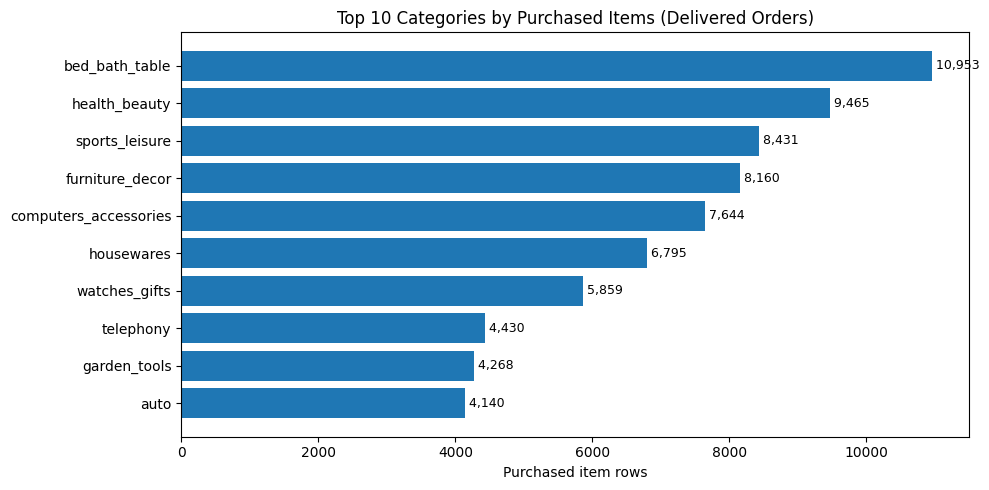

จำนวนหมวดหมู่ทั้งหมด: 74
สัดส่วนรายการซื้อของ Top 10 หมวดหมู่: 63.65%


In [ ]:
import matplotlib.pyplot as plt

category_summary = (
    df_reco
    .groupby("category_for_model")
    .agg(
        item_rows=("order_item_id", "size"),
        unique_orders=("order_id", "nunique"),
        unique_products=("product_id", "nunique"),
    )
    .sort_values("item_rows", ascending=False)
)

top_categories = category_summary.head(10)
display(top_categories)

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(
    top_categories.index[::-1],
    top_categories["item_rows"][::-1],
)
ax.set_xlabel("Purchased item rows")
ax.set_title("Top 10 Categories by Purchased Items (Delivered Orders)")

for y, value in enumerate(top_categories["item_rows"][::-1]):
    ax.text(value, y, f" {value:,}", va="center", fontsize=9)

plt.tight_layout()
plt.show()

top10_share = top_categories["item_rows"].sum() / len(df_reco)
print(f"จำนวนหมวดหมู่ทั้งหมด: {len(category_summary):,}")
print(f"สัดส่วนรายการซื้อของ Top 10 หมวดหมู่: {top10_share:.2%}")

กราฟที่ 2 ความถี่การซื้อต่อผู้ซื้อ

,distinct_products,customers,percent
0,1,88024,94.29
1,2,4574,4.90
2,3,549,0.59
3,4,150,0.16
4,5+,61,0.07


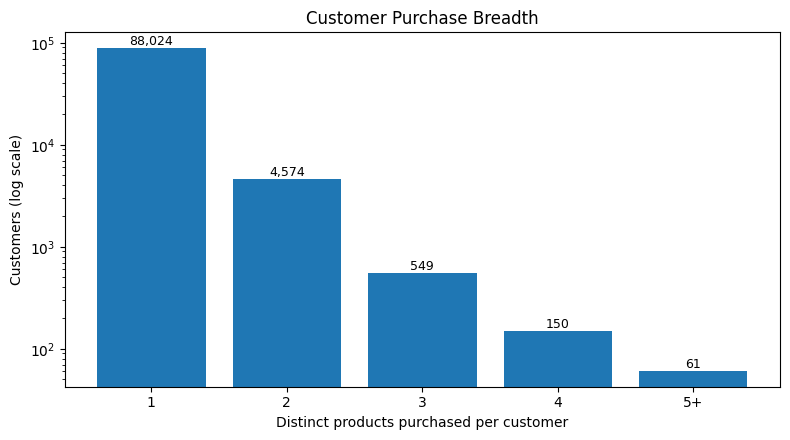

ผู้ซื้อทั้งหมด: 93,358
ผู้ซื้อที่ซื้อสินค้าเพียง 1 ชนิด: 94.29%
ผู้ซื้อที่มีมากกว่า 1 ออเดอร์: 3.00%
สินค้าที่มีผู้ซื้อเพียง 1 คน: 59.52%


In [ ]:
user_activity = (
    df_reco
    .groupby("customer_unique_id")
    .agg(
        n_orders=("order_id", "nunique"),
        n_products=("product_id", "nunique"),
        n_items=("order_item_id", "size"),
    )
)

activity_bucket = pd.cut(
    user_activity["n_products"],
    bins=[0, 1, 2, 3, 4, np.inf],
    labels=["1", "2", "3", "4", "5+"],
)

activity_distribution = (
    activity_bucket
    .value_counts()
    .sort_index()
    .rename_axis("distinct_products")
    .reset_index(name="customers")
)
activity_distribution["percent"] = (
    activity_distribution["customers"]
    .div(len(user_activity))
    .mul(100)
    .round(2)
)

display(activity_distribution)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(
    activity_distribution["distinct_products"].astype(str),
    activity_distribution["customers"],
)
ax.set_yscale("log")
ax.set_xlabel("Distinct products purchased per customer")
ax.set_ylabel("Customers (log scale)")
ax.set_title("Customer Purchase Breadth")

for x, value in enumerate(activity_distribution["customers"]):
    ax.text(x, value, f"{value:,}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

# ความนิยมของสินค้า: สินค้าถูกซื้อโดยผู้ซื้อกี่คน
item_popularity = (
    df_reco.groupby("product_id")["customer_unique_id"].nunique()
)

print(f"ผู้ซื้อทั้งหมด: {len(user_activity):,}")
print(f"ผู้ซื้อที่ซื้อสินค้าเพียง 1 ชนิด: "
      f"{user_activity['n_products'].eq(1).mean():.2%}")
print(f"ผู้ซื้อที่มีมากกว่า 1 ออเดอร์: "
      f"{user_activity['n_orders'].gt(1).mean():.2%}")
print(f"สินค้าที่มีผู้ซื้อเพียง 1 คน: "
      f"{item_popularity.eq(1).mean():.2%}")

## 7. Interaction Data

### นิยาม
หนึ่ง Interaction = ผู้ซื้อ (customer_unique_id) หนึ่งคน กับสินค้า (product_id) หนึ่งชิ้น
ที่เคยซื้อในออเดอร์ delivered อย่างน้อยหนึ่งครั้ง

### คอลัมน์
- interaction: 1 เมื่อเคยซื้อ (Implicit Feedback แบบ Binary)
- purchase_qty: จำนวนชิ้นรวมที่ซื้อ
- n_orders: จำนวนออเดอร์ที่ซื้อสินค้านี้
- first_purchase / last_purchase: เวลาซื้อครั้งแรกและล่าสุด ใช้แบ่ง Train/Test ตามเวลา
- avg_review_score: คะแนนรีวิวเฉลี่ยระดับออเดอร์ ใช้วิเคราะห์ประกอบเท่านั้น

### เหตุผลที่ใช้ customer_unique_id
customer_id เปลี่ยนทุกออเดอร์ ถ้าใช้ customer_id
ผู้ซื้อคนเดิมจะถูกนับเป็นคนละคน และไม่มีประวัติซื้อซ้ำให้เรียนรู้

### เหตุผลที่ใช้ Sparse Matrix
ผู้ซื้อหลายหมื่นคน × สินค้าหลายหมื่นชนิด
หากใช้ pivot_table แบบ Dense จะใช้หน่วยความจำมากเกินไป
จึงเก็บเฉพาะช่องที่มีการซื้อด้วย scipy.sparse.csr_matrix

สร้างตาราง Interaction

In [ ]:
# สินค้าหนึ่งชิ้นต้องมีหมวดหมู่เดียว ก่อนใช้ "first"
assert (
    df_reco.groupby("product_id")["category_for_model"].nunique().eq(1).all()
)

interactions = (
    df_reco
    .groupby(["customer_unique_id", "product_id"], as_index=False)
    .agg(
        purchase_qty=("order_item_id", "size"),
        n_orders=("order_id", "nunique"),
        first_purchase=("order_purchase_timestamp", "min"),
        last_purchase=("order_purchase_timestamp", "max"),
        avg_review_score=("review_score", "mean"),
        category=("category_for_model", "first"),
    )
)

interactions["interaction"] = 1

# ตรวจความถูกต้อง
assert not interactions.duplicated(
    subset=["customer_unique_id", "product_id"]
).any()
assert interactions["purchase_qty"].sum() == len(df_reco)
assert interactions["customer_unique_id"].nunique() == len(user_activity)

print(f"df_reco:      {len(df_reco):,} รายการสินค้า")
print(f"interactions: {len(interactions):,} คู่ ผู้ซื้อ–สินค้า")

display(interactions["purchase_qty"].describe().round(2))
display(interactions.head())

df_reco:      110,197 รายการสินค้า
interactions: 99,785 คู่ ผู้ซื้อ–สินค้า


,purchase_qty
count,99785.00
mean,1.10
std,0.48
min,1.00
25%,1.00
50%,1.00
75%,1.00
max,24.00


,customer_unique_id,product_id,purchase_qty,n_orders,first_purchase,last_purchase,avg_review_score,category,interaction
0,0000366f3b9a7992bf8c76cfdf3221e2,372645c7439f9661fbbacfd129aa92ec,1,1,2018-05-10 10:56:27,2018-05-10 10:56:27,5.0,bed_bath_table,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,5099f7000472b634fea8304448d20825,1,1,2018-05-07 11:11:27,2018-05-07 11:11:27,4.0,health_beauty,1
2,0000f46a3911fa3c0805444483337064,64b488de448a5324c4134ea39c28a34b,1,1,2017-03-10 21:05:03,2017-03-10 21:05:03,3.0,stationery,1
3,0000f6ccb0745a6a4b88665a16c9f078,2345a354a6f2033609bbf62bf5be9ef6,1,1,2017-10-12 20:29:41,2017-10-12 20:29:41,4.0,telephony,1
4,0004aac84e0df4da2b147fca70cf8255,c72e18b3fe2739b8d24ebf3102450f37,1,1,2017-11-14 19:45:42,2017-11-14 19:45:42,5.0,telephony,1


สร้าง Sparse Interaction Matrix

In [ ]:
from scipy.sparse import csr_matrix

user_ids = pd.Index(
    interactions["customer_unique_id"].unique()
).sort_values()
item_ids = pd.Index(
    interactions["product_id"].unique()
).sort_values()

user_to_idx = pd.Series(range(len(user_ids)), index=user_ids)
item_to_idx = pd.Series(range(len(item_ids)), index=item_ids)

row_idx = user_to_idx.loc[interactions["customer_unique_id"]].to_numpy()
col_idx = item_to_idx.loc[interactions["product_id"]].to_numpy()

interaction_matrix = csr_matrix(
    (
        interactions["interaction"].to_numpy(dtype="float32"),
        (row_idx, col_idx),
    ),
    shape=(len(user_ids), len(item_ids)),
)

n_users, n_items = interaction_matrix.shape
density = interaction_matrix.nnz / (n_users * n_items)

assert interaction_matrix.nnz == len(interactions)
assert interaction_matrix.max() == 1

matrix_summary = pd.DataFrame({
    "metric": [
        "Users",
        "Items",
        "Non-zero interactions",
        "Density (%)",
        "Sparsity (%)",
    ],
    "value": [
        f"{n_users:,}",
        f"{n_items:,}",
        f"{interaction_matrix.nnz:,}",
        f"{density * 100:.5f}",
        f"{(1 - density) * 100:.5f}",
    ],
})

display(matrix_summary)

,metric,value
0,Users,"93,358"
1,Items,"32,216"
2,Non-zero interactions,"99,785"
3,Density (%),0.00332
4,Sparsity (%),99.99668


### 7.1 Notes Before Modeling

- interaction_matrix นี้สร้างจากข้อมูลทั้งหมด ใช้เพื่อสำรวจข้อมูลเท่านั้น
- ตอนฝึกและประเมินโมเดล ต้องแบ่ง Train/Test ตามเวลาก่อน
  แล้วสร้าง Matrix จาก Train เท่านั้น เพื่อป้องกัน Data Leakage
- ผู้ซื้อส่วนใหญ่มีประวัติเพียงหนึ่งสินค้า
  จึงต้องมี Baseline เช่น Popularity และ Content-Based
  สำหรับผู้ซื้อที่มีประวัติน้อย (Cold Start)

## 8. Temporal Train/Test Split

### เหตุผลที่แบ่งตามเวลา
ระบบแนะนำจริงต้องใช้ข้อมูลในอดีตเพื่อทำนายการซื้อในอนาคต
การสุ่มแบ่งข้อมูลจะทำให้โมเดลเห็นข้อมูลอนาคต (Data Leakage)

### วิธีแบ่ง
- กำหนดเวลาตัด (cutoff) ที่ควอนไทล์ 85% ของเวลาซื้อ แล้วปัดลงเป็นต้นวัน
- Train: ซื้อก่อน cutoff / Test: ซื้อตั้งแต่ cutoff เป็นต้นไป
- รายการในออเดอร์เดียวกันมีเวลาซื้อเดียวกัน จึงไม่มีออเดอร์ถูกแยกครึ่ง

### ชุดประเมิน (Ground Truth)
- สินค้าที่ผู้ซื้อซื้อในช่วง Test
- ตัดสินค้าที่ผู้ซื้อเคยซื้อแล้วใน Train ออก
  เพราะเราประเมินการแนะนำสินค้าใหม่ ไม่ใช่การซื้อซ้ำ
- แยกผลเป็น Warm Users (มีประวัติใน Train) และ Cold Users (ไม่มีประวัติ)

### ข้อจำกัด
- ข้อมูลรีวิวและคุณลักษณะใดที่เกิดหลัง cutoff ห้ามนำมาใช้ฝึกโมเดล
- สินค้าที่ปรากฏครั้งแรกในช่วง Test ไม่มีโมเดลใดที่ใช้แค่ Train แนะนำได้

แบ่งข้อมูลและสร้าง Ground Truth

In [ ]:
SPLIT_QUANTILE = 0.85

purchase_time = df_reco["order_purchase_timestamp"]
cutoff = purchase_time.quantile(SPLIT_QUANTILE).normalize()

train_df = df_reco.loc[purchase_time < cutoff].copy()
test_df = df_reco.loc[purchase_time >= cutoff].copy()

assert len(train_df) + len(test_df) == len(df_reco)
assert not set(train_df["order_id"]) & set(test_df["order_id"])


def build_interactions(df):
    return (
        df.groupby(["customer_unique_id", "product_id"], as_index=False)
        .agg(
            purchase_qty=("order_item_id", "size"),
            n_orders=("order_id", "nunique"),
            first_purchase=("order_purchase_timestamp", "min"),
            last_purchase=("order_purchase_timestamp", "max"),
        )
    )


train_interactions = build_interactions(train_df)
test_interactions = build_interactions(test_df)

# สินค้าที่ผู้ซื้อแต่ละคนเคยซื้อใน Train
train_seen = (
    train_interactions
    .groupby("customer_unique_id")["product_id"]
    .agg(set)
    .to_dict()
)
train_items = set(train_interactions["product_id"])

test_pairs = test_interactions[["customer_unique_id", "product_id"]].copy()

test_pairs["repeat_purchase"] = [
    item in train_seen.get(user, set())
    for user, item in zip(
        test_pairs["customer_unique_id"], test_pairs["product_id"]
    )
]
test_pairs["item_in_train"] = test_pairs["product_id"].isin(train_items)

eval_pairs = test_pairs.loc[~test_pairs["repeat_purchase"]]

ground_truth = (
    eval_pairs
    .groupby("customer_unique_id")["product_id"]
    .agg(set)
    .to_dict()
)

eval_users = sorted(ground_truth)
warm_users = [u for u in eval_users if u in train_seen]
cold_users = [u for u in eval_users if u not in train_seen]

split_summary = pd.DataFrame({
    "metric": [
        "Cutoff",
        "Train period",
        "Test period",
        "Train item rows",
        "Test item rows",
        "Train users",
        "Train items",
        "Test pairs (all)",
        "Repeat pairs removed",
        "Evaluated users",
        "Warm users",
        "Cold users",
        "Test pairs with item not in Train (%)",
    ],
    "value": [
        str(cutoff.date()),
        f"{train_df['order_purchase_timestamp'].min().date()} → "
        f"{train_df['order_purchase_timestamp'].max().date()}",
        f"{test_df['order_purchase_timestamp'].min().date()} → "
        f"{test_df['order_purchase_timestamp'].max().date()}",
        f"{len(train_df):,}",
        f"{len(test_df):,}",
        f"{len(train_seen):,}",
        f"{len(train_items):,}",
        f"{len(test_pairs):,}",
        f"{int(test_pairs['repeat_purchase'].sum()):,}",
        f"{len(eval_users):,}",
        f"{len(warm_users):,}",
        f"{len(cold_users):,}",
        f"{(~eval_pairs['item_in_train']).mean() * 100:.2f}",
    ],
})

display(split_summary)

,metric,value
0,Cutoff,2018-06-20
1,Train period,2016-09-15 → 2018-06-19
2,Test period,2018-06-20 → 2018-08-29
3,Train item rows,"93,572"
4,Test item rows,"16,625"
5,Train users,"79,146"
6,Train items,"27,462"
7,Test pairs (all),"15,249"
8,Repeat pairs removed,37
9,Evaluated users,"14,507"


## 9. Evaluation Framework

ใช้ K = 10 (แนะนำ 10 สินค้าต่อผู้ซื้อ)

| ตัวชี้วัด | ความหมาย |
|---|---|
| Precision@K | สัดส่วนสินค้าที่แนะนำแล้วผู้ซื้อซื้อจริง |
| Recall@K | สัดส่วนสินค้าที่ผู้ซื้อซื้อจริงและอยู่ในรายการแนะนำ |
| HitRate@K | สัดส่วนผู้ซื้อที่มีสินค้าถูกต้องอย่างน้อยหนึ่งชิ้นในรายการ |
| NDCG@K | เหมือน Recall แต่ให้คะแนนมากขึ้นเมื่อสินค้าที่ถูกอยู่อันดับต้น |
| Item Coverage | สัดส่วนสินค้าใน Train ที่ถูกแนะนำให้ผู้ซื้ออย่างน้อยหนึ่งคน |

ผู้ซื้อส่วนใหญ่ซื้อเพียงหนึ่งสินค้าในช่วง Test
Precision@10 จึงมีค่าสูงสุดได้ประมาณ 0.1 และ HitRate@10 อ่านง่ายที่สุด

ทุกโมเดลจะไม่แนะนำสินค้าที่ผู้ซื้อเคยซื้อแล้วใน Train

ฟังก์ชันประเมินผล

In [ ]:
K = 10


def evaluate_topk(recommend_fn, users, ground_truth, k=K):
    if len(users) == 0:
        return {"users": 0}

    discounts = 1 / np.log2(np.arange(2, k + 2))
    recommended_items = set()
    scores = []

    for user in users:
        truth = ground_truth[user]
        recs = list(recommend_fn(user, k))[:k]
        recommended_items.update(recs)

        hit_flags = np.array([item in truth for item in recs], dtype=float)
        hits = hit_flags.sum()

        dcg = (hit_flags * discounts[: len(recs)]).sum()
        idcg = discounts[: min(len(truth), k)].sum()

        scores.append([
            hits / k,
            hits / len(truth),
            float(hits > 0),
            dcg / idcg,
        ])

    scores = np.array(scores)

    return {
        "users": len(users),
        f"precision@{k}": scores[:, 0].mean(),
        f"recall@{k}": scores[:, 1].mean(),
        f"hit_rate@{k}": scores[:, 2].mean(),
        f"ndcg@{k}": scores[:, 3].mean(),
        "item_coverage": len(recommended_items) / len(train_items),
    }


def make_ranked_recommender(ranking, seen_lookup):
    """แนะนำตามลำดับที่กำหนด โดยข้ามสินค้าที่ผู้ซื้อเคยซื้อใน Train"""
    def recommend(user, k):
        seen = seen_lookup.get(user, set())
        recs = []
        for item in ranking:
            if item not in seen:
                recs.append(item)
                if len(recs) == k:
                    break
        return recs
    return recommend

Random และ Popularity Baseline
ใช้ Baseline 3 แบบ:

*   **Random:** ใช้เช็กว่าฟังก์ชันประเมินผลไม่ผิด เพราะทุกโมเดลต้องได้คะแนนดีกว่านี้ชัดเจน

*   **Popularity (All-time):** สินค้าที่มีผู้ซื้อมากที่สุดตลอดช่วง Train
*   **Popularity (Recent 90 days):** ดูเฉพาะ 90 วันก่อน cutoff เพราะความนิยมสินค้าเปลี่ยนตามเวลา




In [ ]:
RECENT_DAYS = 90
SEED = 42


def popularity_ranking(df, start=None, top_n=500):
    data = df if start is None else df.loc[
        df["order_purchase_timestamp"] >= start
    ]
    return (
        data.groupby("product_id")["customer_unique_id"]
        .nunique()
        .sort_values(ascending=False, kind="mergesort")
        .head(top_n)
        .index
        .tolist()
    )


pop_all_ranking = popularity_ranking(train_df)
pop_recent_ranking = popularity_ranking(
    train_df, start=cutoff - pd.Timedelta(days=RECENT_DAYS)
)

train_item_array = np.array(sorted(train_items))
rng = np.random.default_rng(SEED)


def random_recommend(user, k):
    seen = train_seen.get(user, set())
    recs = []
    while len(recs) < k:
        for idx in rng.integers(0, len(train_item_array), size=k * 3):
            item = train_item_array[idx]
            if item not in seen and item not in recs:
                recs.append(item)
                if len(recs) == k:
                    break
    return recs


baselines = {
    "Random": random_recommend,
    "Popularity (All-time)": make_ranked_recommender(
        pop_all_ranking, train_seen
    ),
    f"Popularity (Recent {RECENT_DAYS}d)": make_ranked_recommender(
        pop_recent_ranking, train_seen
    ),
}

user_groups = {
    "All": eval_users,
    "Warm": warm_users,
    "Cold": cold_users,
}

result_rows = []

for model_name, recommend_fn in baselines.items():
    for group_name, users in user_groups.items():
        result = evaluate_topk(recommend_fn, users, ground_truth)
        result_rows.append({
            "model": model_name,
            "user_group": group_name,
            **result,
        })

baseline_results = pd.DataFrame(result_rows).round(4)
display(baseline_results)

# ดูว่า Top 10 ยอดนิยมล่าสุดเป็นสินค้าหมวดไหน
top_recent_items = (
    df_reco.loc[
        df_reco["product_id"].isin(pop_recent_ranking[:K]),
        ["product_id", "category_for_model"],
    ]
    .drop_duplicates("product_id")
    .set_index("product_id")
    .loc[pop_recent_ranking[:K]]
    .reset_index()
)
display(top_recent_items)

,model,user_group,users,precision@10,recall@10,hit_rate@10,ndcg@10,item_coverage
0,Random,All,14507,0.0000,0.0003,0.0003,0.0001,0.9951
1,Random,Warm,295,0.0000,0.0000,0.0000,0.0000,0.1023
2,Random,Cold,14212,0.0000,0.0004,0.0004,0.0002,0.9939
3,Popularity (All-time),All,14507,0.0011,0.0105,0.0108,0.0049,0.0004
4,Popularity (All-time),Warm,295,0.0014,0.0096,0.0136,0.0039,0.0004
5,Popularity (All-time),Cold,14212,0.0011,0.0105,0.0108,0.0049,0.0004
6,Popularity (Recent 90d),All,14507,0.0018,0.0177,0.0181,0.0074,0.0004
7,Popularity (Recent 90d),Warm,295,0.0024,0.0198,0.0237,0.0086,0.0004
8,Popularity (Recent 90d),Cold,14212,0.0018,0.0177,0.0179,0.0074,0.0004


,product_id,category_for_model
0,53b36df67ebb7c41585e8d54d6772e08,watches_gifts
1,aca2eb7d00ea1a7b8ebd4e68314663af,furniture_decor
2,3dd2a17168ec895c781a9191c1e95ad7,computers_accessories
3,d1c427060a0f73f6b889a5c7c61f2ac4,computers_accessories
4,422879e10f46682990de24d770e7f83d,garden_tools
5,3fbc0ef745950c7932d5f2a446189725,health_beauty
6,19c91ef95d509ea33eda93495c4d3481,health_beauty
7,a62e25e09e05e6faf31d90c6ec1aa3d1,watches_gifts
8,e0d64dcfaa3b6db5c54ca298ae101d05,watches_gifts
9,2948658cb6abc82847412be7201bfc4c,health_beauty


### 9.1 Baseline Interpretation

- Popularity ต้องได้คะแนนสูงกว่า Random อย่างชัดเจน
  หากไม่เป็นเช่นนั้น ให้ตรวจสอบการแบ่งข้อมูลหรือฟังก์ชันประเมินผล
- เปรียบเทียบ All-time กับ Recent เพื่อดูว่าความนิยมเปลี่ยนตามเวลาหรือไม่
- Cold Users มีจำนวนมากที่สุด และใช้ได้เฉพาะโมเดลที่ไม่ต้องอาศัยประวัติ
- โมเดลถัดไปต้องเอาชนะ Popularity ที่ดีที่สุด
  อย่างน้อยในกลุ่ม Warm Users จึงจะถือว่ามีประโยชน์

# **CAPTURE HERE**

### 9.2 Split & Baseline Findings

- Cutoff = 2018-06-20 (Train: 2016-09-15 → 2018-06-19, Test: 2018-06-20 → 2018-08-29)
- ผู้ซื้อที่ใช้ประเมิน 14,507 คน เป็น Cold Users 14,212 คน (98%)
  และ Warm Users เพียง 295 คน
- คู่ที่ใช้ประเมิน 41.39% เป็นสินค้าที่ไม่ปรากฏใน Train
  ไม่มีโมเดลที่ใช้เฉพาะ Train ใดแนะนำสินค้ากลุ่มนี้ได้
- Popularity (Recent 90d) ดีที่สุดในกลุ่ม Baseline
  HitRate@10 = 0.0181 (All) และ 0.0237 (Warm) เทียบกับ Random ≈ 0
- ความนิยมล่าสุดดีกว่าความนิยมตลอดช่วง แสดงว่าความนิยมสินค้าเปลี่ยนตามเวลา
- Item Coverage ของ Popularity = 0.0004 (ผู้ซื้อทุกคนได้รายการเกือบเหมือนกัน)

## 10. Personalized Models

| โมเดล | แนวคิด | ใช้กับ |
|---|---|---|
| Item-based CF | แนะนำสินค้าที่มักถูกซื้อโดยผู้ซื้อกลุ่มเดียวกัน (Cosine Similarity) | Warm Users |
| Category-Based | แนะนำสินค้ายอดนิยมในหมวดหมู่ที่ผู้ซื้อเคยซื้อ | Warm Users |
| Hybrid | ใช้ CF ก่อน แล้วเติมด้วย Category และ Popularity ตามลำดับ | ทุกคน |

- ทุกโมเดลสร้างจาก Train เท่านั้น
- เมื่อหาสินค้าได้ไม่ครบ 10 ชิ้น จะเติมด้วย Popularity (Recent 90d)
- Cold Users ไม่มีประวัติ ทุกโมเดลจึงเหลือแค่ Popularity
  การเปรียบเทียบหลักจึงทำในกลุ่ม Warm Users พร้อม Bootstrap CI

สร้าง Train Matrix และ Item Similarity

In [ ]:
from scipy.sparse import diags
from sklearn.preprocessing import normalize

train_user_ids = pd.Index(
    sorted(train_interactions["customer_unique_id"].unique())
)
train_item_ids = pd.Index(
    sorted(train_interactions["product_id"].unique())
)

train_user_idx = pd.Series(np.arange(len(train_user_ids)), index=train_user_ids)
train_item_idx = pd.Series(np.arange(len(train_item_ids)), index=train_item_ids)

rows = train_user_idx.loc[train_interactions["customer_unique_id"]].to_numpy()
cols = train_item_idx.loc[train_interactions["product_id"]].to_numpy()

X_train = csr_matrix(
    (np.ones(len(rows), dtype="float32"), (rows, cols)),
    shape=(len(train_user_ids), len(train_item_ids)),
)

assert X_train.nnz == len(train_interactions)
assert X_train.shape == (len(train_seen), len(train_items))

# Cosine Similarity ระหว่างสินค้า: normalize ตามคอลัมน์ แล้วคูณกัน
X_norm = normalize(X_train, norm="l2", axis=0)
item_sim = (X_norm.T @ X_norm).tocsr()

# ตัดความคล้ายของสินค้ากับตัวเองออก
item_sim = (item_sim - diags(item_sim.diagonal())).tocsr()
item_sim.eliminate_zeros()

items_with_neighbors = np.diff(item_sim.indptr) > 0

print(f"Train matrix: {X_train.shape[0]:,} users × {X_train.shape[1]:,} items")
print(f"คู่สินค้าที่มีความคล้าย > 0: {item_sim.nnz:,}")
print(f"สินค้าที่มีสินค้าคล้ายอย่างน้อย 1 ชิ้น: {items_with_neighbors.mean():.2%}")

Train matrix: 79,146 users × 27,462 items
คู่สินค้าที่มีความคล้าย > 0: 12,604
สินค้าที่มีสินค้าคล้ายอย่างน้อย 1 ชิ้น: 23.96%


ฟังก์ชันแนะนำของแต่ละโมเดล

In [ ]:
def item_cf_recommend(user, k):
    """คืนเฉพาะสินค้าที่มีคะแนน CF > 0 ซึ่งอาจได้น้อยกว่า k"""
    if user not in train_user_idx.index:
        return []

    u = train_user_idx[user]
    user_row = X_train[u]

    scores = (user_row @ item_sim).toarray().ravel()
    scores[user_row.indices] = 0  # ไม่แนะนำสินค้าที่เคยซื้อแล้ว

    candidates = np.flatnonzero(scores > 0)
    if len(candidates) == 0:
        return []

    order = candidates[np.argsort(-scores[candidates], kind="mergesort")]
    return train_item_ids[order[:k]].tolist()


# ---------- Category-Based ----------
recent_start = cutoff - pd.Timedelta(days=RECENT_DAYS)

item_category = (
    train_df.drop_duplicates("product_id")
    .set_index("product_id")["category_for_model"]
)

item_pop = pd.DataFrame({
    "recent_buyers": (
        train_df.loc[train_df["order_purchase_timestamp"] >= recent_start]
        .groupby("product_id")["customer_unique_id"].nunique()
    ),
    "all_time_buyers": (
        train_df.groupby("product_id")["customer_unique_id"].nunique()
    ),
}).fillna(0)

item_pop["category"] = item_category
item_pop = item_pop.sort_values(
    ["recent_buyers", "all_time_buyers"],
    ascending=False,
    kind="mergesort",
)

# groupby คงลำดับเดิมภายในกลุ่ม จึงได้สินค้าเรียงตามความนิยมในแต่ละหมวด
category_rankings = {
    cat: group.index[:500].tolist()
    for cat, group in item_pop.groupby("category", sort=False)
}

# หมวดหมู่ที่ผู้ซื้อแต่ละคนเคยซื้อ เรียงจากซื้อมากไปน้อย (ไม่ใช้ unknown)
user_categories = (
    train_interactions
    .assign(category=lambda d: d["product_id"].map(item_category))
    .loc[lambda d: d["category"].ne("unknown")]
    .groupby(["customer_unique_id", "category"])
    .size()
    .reset_index(name="n")
    .sort_values(["customer_unique_id", "n"], ascending=[True, False])
    .groupby("customer_unique_id")["category"]
    .agg(list)
    .to_dict()
)


def category_recommend(user, k):
    seen = train_seen.get(user, set())
    recs = []
    for cat in user_categories.get(user, []):
        for item in category_rankings.get(cat, []):
            if item not in seen and item not in recs:
                recs.append(item)
                if len(recs) == k:
                    return recs
    return recs


# ---------- รวมหลายแหล่ง ----------
pop_recent_fill = make_ranked_recommender(pop_recent_ranking, train_seen)


def combine(*recommenders):
    """ดึงสินค้าจากแต่ละแหล่งตามลำดับจนครบ k โดยไม่ซ้ำกัน"""
    def recommend(user, k):
        recs = []
        for fn in recommenders:
            for item in fn(user, k):
                if item not in recs:
                    recs.append(item)
                    if len(recs) == k:
                        return recs
        return recs
    return recommend


models = {
    f"Popularity (Recent {RECENT_DAYS}d)": pop_recent_fill,
    "Category-Based + Pop": combine(category_recommend, pop_recent_fill),
    "Item-CF + Pop": combine(item_cf_recommend, pop_recent_fill),
    "Hybrid (CF → Category → Pop)": combine(
        item_cf_recommend, category_recommend, pop_recent_fill
    ),
}

# ตรวจกับ Warm Users ทุกคน (มีเพียง 295 คน จึงรันได้เร็ว)
for name, fn in models.items():
    for user in warm_users:
        recs = fn(user, K)
        assert len(recs) == K, name
        assert len(set(recs)) == K, name
        assert not set(recs) & train_seen.get(user, set()), name

print("ผ่าน: ทุกโมเดลคืนสินค้าครบ ไม่ซ้ำ และไม่มีสินค้าที่เคยซื้อ")

ผ่าน: ทุกโมเดลคืนสินค้าครบ ไม่ซ้ำ และไม่มีสินค้าที่เคยซื้อ


ประเมินผล

In [ ]:
cf_reach = np.mean([len(item_cf_recommend(u, K)) > 0 for u in warm_users])
cat_reach = np.mean([len(category_recommend(u, K)) > 0 for u in warm_users])

print(f"Warm Users ที่ CF หาสินค้าได้อย่างน้อย 1 ชิ้น: {cf_reach:.2%}")
print(f"Warm Users ที่ Category-Based หาสินค้าได้: {cat_reach:.2%}")

model_rows = []
for name, fn in models.items():
    for group_name in ["Warm", "All"]:
        result = evaluate_topk(fn, user_groups[group_name], ground_truth)
        model_rows.append({"model": name, "user_group": group_name, **result})

model_results = pd.DataFrame(model_rows).round(4)
display(model_results)

Warm Users ที่ CF หาสินค้าได้อย่างน้อย 1 ชิ้น: 46.78%
Warm Users ที่ Category-Based หาสินค้าได้: 98.31%


,model,user_group,users,precision@10,recall@10,hit_rate@10,ndcg@10,item_coverage
0,Popularity (Recent 90d),Warm,295,0.0024,0.0198,0.0237,0.0086,0.0004
1,Popularity (Recent 90d),All,14507,0.0018,0.0177,0.0181,0.0074,0.0004
2,Category-Based + Pop,Warm,295,0.0020,0.0203,0.0203,0.0108,0.0157
3,Category-Based + Pop,All,14507,0.0018,0.0177,0.0180,0.0075,0.0157
4,Item-CF + Pop,Warm,295,0.0024,0.0198,0.0237,0.0074,0.0154
5,Item-CF + Pop,All,14507,0.0018,0.0177,0.0181,0.0074,0.0154
6,Hybrid (CF → Category → Pop),Warm,295,0.0017,0.0169,0.0169,0.0084,0.0282
7,Hybrid (CF → Category → Pop),All,14507,0.0018,0.0176,0.0179,0.0074,0.0282


Bootstrap Confidence Interval

In [ ]:
N_BOOT = 2000


def per_user_hits(recommend_fn, users, k=K):
    return np.array([
        float(any(item in ground_truth[u] for item in recommend_fn(u, k)))
        for u in users
    ])


def bootstrap_ci(values, n_boot=N_BOOT, seed=SEED):
    rng_boot = np.random.default_rng(seed)
    idx = rng_boot.integers(0, len(values), size=(n_boot, len(values)))
    means = values[idx].mean(axis=1)
    return np.percentile(means, [2.5, 97.5])


baseline_name = f"Popularity (Recent {RECENT_DAYS}d)"
warm_hits = {name: per_user_hits(fn, warm_users) for name, fn in models.items()}

ci_rows = []
for name, hits in warm_hits.items():
    low, high = bootstrap_ci(hits)
    diff = hits - warm_hits[baseline_name]  # เทียบกับผู้ซื้อคนเดียวกัน (paired)
    d_low, d_high = bootstrap_ci(diff)

    ci_rows.append({
        "model": name,
        "hits": int(hits.sum()),
        "hit_rate@10": hits.mean(),
        "ci_95_low": low,
        "ci_95_high": high,
        "diff_vs_pop": diff.mean(),
        "diff_ci_low": d_low,
        "diff_ci_high": d_high,
    })

warm_ci = pd.DataFrame(ci_rows).round(4)
display(warm_ci)

,model,hits,hit_rate@10,ci_95_low,ci_95_high,diff_vs_pop,diff_ci_low,diff_ci_high
0,Popularity (Recent 90d),7,0.0237,0.0068,0.0441,0.0000,0.0000,0.0000
1,Category-Based + Pop,6,0.0203,0.0068,0.0373,-0.0034,-0.0237,0.0169
2,Item-CF + Pop,7,0.0237,0.0068,0.0441,0.0000,0.0000,0.0000
3,Hybrid (CF → Category → Pop),5,0.0169,0.0034,0.0339,-0.0068,-0.0271,0.0102


### 10.1 Model Comparison

- เปรียบเทียบหลักในกลุ่ม Warm Users (295 คน)
  เพราะ Cold Users ทุกโมเดลเหลือแค่ Popularity
- ใช้ Bootstrap 95% CI ของผลต่าง HitRate เทียบกับ Popularity (Recent 90d)
  หากช่วงคร่อม 0 ถือว่ายังไม่มีหลักฐานเพียงพอว่าดีกว่า
- พิจารณา Item Coverage ร่วมด้วย
  โมเดลที่คะแนนใกล้เคียงกันแต่ Coverage สูงกว่า กระจายการแนะนำได้ดีกว่า
- ข้อจำกัด: Warm Users มีน้อย และ 41.39% ของคู่ที่ใช้ประเมิน
  เป็นสินค้าที่ไม่มีใน Train

### 10.2 Model Selection

ผลในกลุ่ม Warm Users (295 คน):
- ไม่มีโมเดลใดดีกว่า Popularity (Recent 90d) อย่างมีนัยสำคัญ
  (Bootstrap 95% CI ของผลต่าง HitRate คร่อม 0 ทุกโมเดล)
- Item-CF + Pop แนะนำถูก 7 คน เท่ากับ Popularity
  แต่ Item Coverage สูงกว่าประมาณ 33 เท่า (0.0134 เทียบกับ 0.0004)
- Category-Based และ Hybrid มี Coverage สูงกว่า
  แต่แนะนำถูกลดลงเหลือ 6 และ 5 คน

โมเดลที่เลือก: Item-CF + Pop
- ผู้ซื้อที่มีประวัติ: แนะนำสินค้าคล้ายกับที่เคยซื้อ แล้วเติมด้วยสินค้ายอดนิยมล่าสุด
- ผู้ซื้อใหม่: แนะนำสินค้ายอดนิยมใน 90 วันล่าสุด

ข้อจำกัด: ใช้ชุด Test ทั้งเลือกโมเดลและรายงานผล
เนื่องจาก Warm Users มีน้อยเกินกว่าจะแยกชุด Validation

กราฟเปรียบเทียบโมเดล (สำหรับรายงาน)

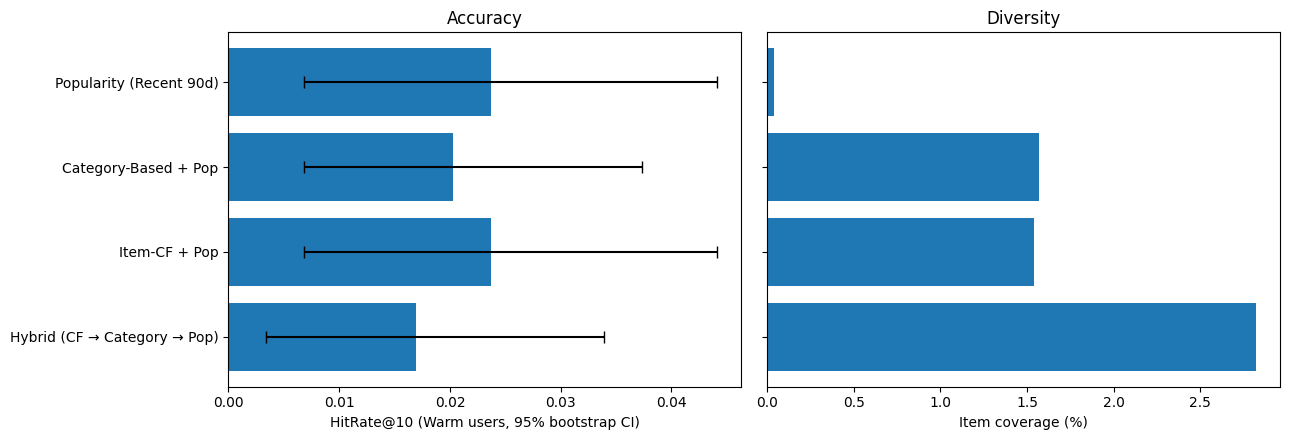

In [ ]:
plot_df = warm_ci.merge(
    model_results.loc[
        model_results["user_group"].eq("Warm"),
        ["model", "item_coverage"],
    ],
    on="model",
)

y = np.arange(len(plot_df))
err = np.vstack([
    plot_df["hit_rate@10"] - plot_df["ci_95_low"],
    plot_df["ci_95_high"] - plot_df["hit_rate@10"],
]).clip(min=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].barh(y, plot_df["hit_rate@10"], xerr=err, capsize=4)
axes[0].set_yticks(y, plot_df["model"])
axes[0].invert_yaxis()
axes[0].set_xlabel("HitRate@10 (Warm users, 95% bootstrap CI)")
axes[0].set_title("Accuracy")

axes[1].barh(y, plot_df["item_coverage"] * 100)
axes[1].set_yticks(y, [])
axes[1].invert_yaxis()
axes[1].set_xlabel("Item coverage (%)")
axes[1].set_title("Diversity")

plt.tight_layout()
plt.show()

## 11. Final Model

ประเมินผลด้วย Train แล้ว ก่อนนำไปใช้งานจริงจะฝึกโมเดลใหม่ด้วยข้อมูลทั้งหมด (df_reco)
เพื่อให้โมเดลรู้จักผู้ซื้อและสินค้าล่าสุด

ขั้นตอน:
1. เขียนโมเดลเป็นฟังก์ชันที่ไม่พึ่งตัวแปรใน Notebook
2. ทดสอบว่าเมื่อใช้ train_df แล้ว ฟังก์ชันใหม่ให้ผลตรงกับ Item-CF + Pop ทุกคน
3. ฝึกใหม่ด้วย df_reco แล้วบันทึกเป็นไฟล์สำหรับ API

ไฟล์โมเดลเก็บเป็นข้อมูลล้วน (Matrix, ID และลำดับความนิยม)
ไม่ได้เก็บเป็น Object ของ Class เพื่อให้ API โหลดได้โดยไม่ต้องมีโค้ดจาก Notebook

ฟังก์ชันสร้างและใช้งานโมเดล

In [ ]:
import joblib
from pathlib import Path


def build_artifacts(df, recent_days=RECENT_DAYS, pop_size=500):
    # groupby เรียงตาม ID เหมือน build_interactions เพื่อให้ผลตรงกับตอนประเมิน
    pairs = (
        df.groupby(["customer_unique_id", "product_id"])
        .size()
        .reset_index(name="n")
    )

    user_ids = pd.Index(sorted(pairs["customer_unique_id"].unique()))
    item_ids = pd.Index(sorted(pairs["product_id"].unique()))
    user_pos = pd.Series(np.arange(len(user_ids)), index=user_ids)
    item_pos = pd.Series(np.arange(len(item_ids)), index=item_ids)

    X = csr_matrix(
        (
            np.ones(len(pairs), dtype="float32"),
            (
                user_pos.loc[pairs["customer_unique_id"]].to_numpy(),
                item_pos.loc[pairs["product_id"]].to_numpy(),
            ),
        ),
        shape=(len(user_ids), len(item_ids)),
    )

    X_norm = normalize(X, norm="l2", axis=0)
    sim = (X_norm.T @ X_norm).tocsr()
    sim = (sim - diags(sim.diagonal())).tocsr()
    sim.eliminate_zeros()

    # วันอ้างอิง = วันถัดจากวันซื้อล่าสุด (ตรงกับ cutoff เมื่อใช้ train_df)
    reference_date = (
        df["order_purchase_timestamp"].max().normalize()
        + pd.Timedelta(days=1)
    )

    pop_ranking = popularity_ranking(
        df,
        start=reference_date - pd.Timedelta(days=recent_days),
        top_n=pop_size,
    )

    item_category = (
        df.drop_duplicates("product_id")
        .set_index("product_id")["category_for_model"]
        .to_dict()
    )

    return {
        "model_name": "Item-CF + Popularity (Recent)",
        "trained_until": str(df["order_purchase_timestamp"].max()),
        "reference_date": reference_date,
        "recent_days": recent_days,
        "user_index": dict(zip(user_ids, range(len(user_ids)))),
        "item_ids": np.asarray(item_ids, dtype=object),
        "X": X,
        "item_sim": sim,
        "pop_ranking": pop_ranking,
        "item_category": item_category,
    }


def recommend_from_artifacts(art, customer_id, k=10):
    item_ids = art["item_ids"]
    u = art["user_index"].get(customer_id)

    recs = []
    seen = set()

    if u is not None:
        user_row = art["X"][u]
        seen = set(item_ids[user_row.indices])

        scores = (user_row @ art["item_sim"]).toarray().ravel()
        scores[user_row.indices] = 0

        candidates = np.flatnonzero(scores > 0)
        order = candidates[
            np.argsort(-scores[candidates], kind="mergesort")
        ][:k]

        recs = [
            (item_ids[i], "similar_items", round(float(scores[i]), 4))
            for i in order
        ]

    chosen = {item for item, _, _ in recs}

    for item in art["pop_ranking"]:
        if len(recs) >= k:
            break
        if item not in seen and item not in chosen:
            recs.append((item, "popular_recent", None))
            chosen.add(item)

    return [
        {
            "rank": rank,
            "product_id": item,
            "category": art["item_category"].get(item, "unknown"),
            "source": source,
            "score": score,
        }
        for rank, (item, source, score) in enumerate(recs, start=1)
    ]

ทดสอบว่าฟังก์ชันใหม่ให้ผลตรงกับตอนประเมิน

In [ ]:
art_train = build_artifacts(train_df)

assert art_train["X"].shape == X_train.shape
assert art_train["reference_date"] == cutoff


def rec_ids(art, user):
    return [r["product_id"] for r in recommend_from_artifacts(art, user, K)]


reference_fn = models["Item-CF + Pop"]

mismatch_warm = [
    u for u in warm_users
    if rec_ids(art_train, u) != reference_fn(u, K)
]
mismatch_cold = [
    u for u in cold_users[:500]
    if rec_ids(art_train, u) != reference_fn(u, K)
]

assert not mismatch_warm, f"Warm ไม่ตรง {len(mismatch_warm)} คน"
assert not mismatch_cold, f"Cold ไม่ตรง {len(mismatch_cold)} คน"

print("ผ่าน: ฟังก์ชันใหม่ให้ผลตรงกับโมเดลที่ประเมินทุกคน")

ผ่าน: ฟังก์ชันใหม่ให้ผลตรงกับโมเดลที่ประเมินทุกคน


ฝึกใหม่ด้วยข้อมูลทั้งหมดและบันทึกไฟล์

In [ ]:
artifacts = build_artifacts(df_reco)

# ต้องมีขนาดเท่ากับ interaction_matrix จาก Cell 42
assert artifacts["X"].shape == interaction_matrix.shape

pick = warm_ci.set_index("model").loc["Item-CF + Pop"]
artifacts["evaluation"] = {
    "cutoff": str(cutoff.date()),
    "warm_users": len(warm_users),
    "warm_hit_rate@10": float(pick["hit_rate@10"]),
    "warm_hit_rate_ci95": [float(pick["ci_95_low"]), float(pick["ci_95_high"])],
}

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)
MODEL_PATH = MODEL_DIR / "recommender_itemcf_v1.joblib"

joblib.dump(artifacts, MODEL_PATH, compress=3)
model = joblib.load(MODEL_PATH)

# ตรวจว่าไฟล์ที่โหลดกลับมาให้ผลเหมือนเดิม
for u in list(model["user_index"])[:200]:
    assert rec_ids(model, u) == rec_ids(artifacts, u)

print(f"บันทึกไฟล์: {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1e6:.2f} MB)")
print(f"ผู้ซื้อ: {len(model['user_index']):,} | สินค้า: {len(model['item_ids']):,}")
print(f"ข้อมูลถึง: {model['trained_until']}")
print(f"ช่วงความนิยมล่าสุด: {model['reference_date'] - pd.Timedelta(days=RECENT_DAYS):%Y-%m-%d} "
      f"→ {model['reference_date']:%Y-%m-%d}")

บันทึกไฟล์: models/recommender_itemcf_v1.joblib (3.75 MB)
ผู้ซื้อ: 93,358 | สินค้า: 32,216
ข้อมูลถึง: 2018-08-29 15:00:37
ช่วงความนิยมล่าสุด: 2018-06-01 → 2018-08-30


ทดลองใช้งานและวัดความเร็ว



In [ ]:
import time


def recommend_for_customer(customer_id, k=10, art=model):
    return pd.DataFrame(recommend_from_artifacts(art, customer_id, k))


# ผู้ซื้อที่มีประวัติ และ CF หาสินค้าคล้ายได้
multi_buyers = user_activity.query("n_products >= 2").index
demo_user = next(
    u for u in multi_buyers
    if recommend_from_artifacts(model, u, K)[0]["source"] == "similar_items"
)

print("ประวัติการซื้อ:")
display(
    df_reco.loc[
        df_reco["customer_unique_id"].eq(demo_user),
        ["order_purchase_timestamp", "product_id", "category_for_model"],
    ]
    .drop_duplicates("product_id")
    .sort_values("order_purchase_timestamp")
)

print("รายการแนะนำ:")
display(recommend_for_customer(demo_user))

print("ผู้ซื้อใหม่ (ไม่มีประวัติ):")
display(recommend_for_customer("new_customer_demo"))

# วัดความเร็วต่อคำขอ
sample_users = list(model["user_index"])[:1000]
start = time.perf_counter()
for u in sample_users:
    recommend_from_artifacts(model, u, K)
elapsed_ms = (time.perf_counter() - start) / len(sample_users) * 1000

print(f"เวลาเฉลี่ยต่อคำขอ: {elapsed_ms:.2f} ms")

ประวัติการซื้อ:


,order_purchase_timestamp,product_id,category_for_model
29664,2018-02-28 11:15:41,62984ea1bba7fcea1f5b57084d3bf885,sports_leisure
29665,2018-02-28 11:15:41,58727e154e8e85d84052cd22b0136c84,sports_leisure


รายการแนะนำ:


,rank,product_id,category,source,score
0,1,71b7bb7d435217ef96c1ec8e48421599,sports_leisure,similar_items,0.2887
1,2,19c91ef95d509ea33eda93495c4d3481,health_beauty,popular_recent,NaN
2,3,a92930c327948861c015c919a0bcb4a8,watches_gifts,popular_recent,NaN
3,4,3fbc0ef745950c7932d5f2a446189725,health_beauty,popular_recent,NaN
4,5,e7cc48a9daff5436f63d3aad9426f28b,telephony,popular_recent,NaN
5,6,2fea0f2cec6b6324a277d4a61c2ed2c6,health_beauty,popular_recent,NaN
6,7,fbce4c4cb307679d89a3bf3d3bb353b9,bed_bath_table,popular_recent,NaN
7,8,d04857e7b4b708ee8b8b9921163edba3,computers_accessories,popular_recent,NaN
8,9,73326828aa5efe1ba096223de496f596,food,popular_recent,NaN
9,10,bb50f2e236e5eea0100680137654686c,health_beauty,popular_recent,NaN


ผู้ซื้อใหม่ (ไม่มีประวัติ):


,rank,product_id,category,source,score
0,1,19c91ef95d509ea33eda93495c4d3481,health_beauty,popular_recent,None
1,2,a92930c327948861c015c919a0bcb4a8,watches_gifts,popular_recent,None
2,3,3fbc0ef745950c7932d5f2a446189725,health_beauty,popular_recent,None
3,4,e7cc48a9daff5436f63d3aad9426f28b,telephony,popular_recent,None
4,5,2fea0f2cec6b6324a277d4a61c2ed2c6,health_beauty,popular_recent,None
5,6,fbce4c4cb307679d89a3bf3d3bb353b9,bed_bath_table,popular_recent,None
6,7,d04857e7b4b708ee8b8b9921163edba3,computers_accessories,popular_recent,None
7,8,73326828aa5efe1ba096223de496f596,food,popular_recent,None
8,9,bb50f2e236e5eea0100680137654686c,health_beauty,popular_recent,None
9,10,4fe644d766c7566dbc46fb851363cb3b,art,popular_recent,None


เวลาเฉลี่ยต่อคำขอ: 0.24 ms


## 12. Conclusion

### ผลลัพธ์
- โมเดลสุดท้าย: Item-based CF เติมด้วย Popularity (Recent 90d)
- กลุ่ม Warm Users: HitRate@10 = 0.0237 (95% CI 0.0068–0.0441)
  เท่ากับ Popularity แต่ Item Coverage สูงกว่าประมาณ 33 เท่า
- ไม่มีโมเดลใดดีกว่า Popularity อย่างมีนัยสำคัญ

### ข้อค้นพบ
- ผู้ซื้อ 94.29% ซื้อสินค้าเพียงชนิดเดียว และ Matrix มี Sparsity 99.997%
- ผู้ซื้อที่ใช้ประเมิน 98% ไม่มีประวัติใน Train (Cold Start)
- คู่ที่ใช้ประเมิน 41.39% เป็นสินค้าที่ไม่เคยปรากฏใน Train
- ข้อมูลลักษณะนี้ทำให้ Popularity เป็น Baseline ที่เอาชนะได้ยาก

### ข้อจำกัด
- Warm Users มีเพียง 295 คน ผลจึงมีความไม่แน่นอนสูง
- ใช้ชุด Test ทั้งเลือกโมเดลและรายงานผล (ไม่มีชุด Validation แยก)
- การซื้อเป็น Implicit Feedback ไม่ได้แปลว่าผู้ซื้อชอบสินค้าเสมอไป
- "Real-time" หมายถึงการตอบผลแนะนำทันทีผ่าน API
  ส่วนโมเดลฝึกใหม่เป็นรอบ (Batch) ไม่ได้อัปเดตทันทีเมื่อมีการซื้อ

### แนวทางพัฒนาต่อ
- ใช้ข้อมูลการเข้าชมหรือการใส่ตะกร้า เพื่อเพิ่มจำนวน Interaction
- ใช้ Content-Based จากข้อความหรือรูปภาพ สำหรับสินค้าใหม่
- ทดสอบกับผู้ใช้จริงด้วย A/B Testing

In [ ]:
from google.colab import files
files.download("models/recommender_itemcf_v1.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy, scipy, pandas, joblib
from google.colab import files

# เวอร์ชันต้องตรงกับ Colab ไม่อย่างนั้นอาจโหลดไฟล์โมเดลไม่ได้
req = f"""numpy=={numpy.__version__}
scipy=={scipy.__version__}
pandas=={pandas.__version__}
joblib=={joblib.__version__}
streamlit
fastapi
uvicorn
"""
Path("requirements.txt").write_text(req)
print(req)

files.download("requirements.txt")
files.download(str(MODEL_PATH))

numpy==2.1.3
scipy==1.16.3
pandas==2.2.3
joblib==1.6.0
streamlit
fastapi
uvicorn



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>